# EDA: ซากดึกดำบรรพ์ในประเทศไทย

สำรวจข้อมูลซากดึกดำบรรพ์ในไทยจากข้อมูลฐานหลัก 2 ชุดของกรมทรัพยากรธรณี (ทธ.)

| ชุดข้อมูล | ไฟล์ | หน่วยข้อมูล | มีพิกัด |
|---|---|---|---|
| **ทะเบียนตัวอย่างซากดึกดำบรรพ์** | `data/0301010101_fossil_list-31072567.csv` | ตัวอย่าง 1 ชิ้น | ✗ (มีแค่จังหวัด/อำเภอ/ตำบล) |
| **แหล่งซากดึกดำบรรพ์** | `data/dmr_fossil_sites/fossil_sites.geojson` | แหล่ง 1 แห่ง | ✓ |

ข้อมูลประกอบ: แผนที่หน่วยหิน 1:250,000 (`data/dmr_geology/`) ใช้ระบุหน่วยหินและอายุใต้แต่ละแหล่ง

**สารบัญ**
1. โหลดและทำความสะอาดทะเบียนตัวอย่าง
2. EDA ทะเบียนตัวอย่าง
3. โหลดและทำความสะอาดแหล่งซากดึกดำบรรพ์
4. EDA แหล่งซากดึกดำบรรพ์
5. บริบทธรณีวิทยา: แหล่งซากดึกดำบรรพ์ × แผนที่หน่วยหิน
6. เชื่อมสองชุดข้อมูล (จังหวัด / อำเภอ)
7. สรุปข้อค้นพบและปัญหาคุณภาพข้อมูล

In [1]:
import csv
import io
import re
import unicodedata
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

DATA = Path("../data")
FOSSIL_LIST = DATA / "0301010101_fossil_list-31072567.csv"
SITES = DATA / "dmr_fossil_sites" / "fossil_sites.geojson"
ROCK_UNITS = DATA / "dmr_geology" / "rock_unit_250k.geojson"
ROCK_LEGEND = DATA / "dmr_geology" / "rock_unit_250k_legend.csv"

# ฟอนต์ที่แสดงภาษาไทยได้ (เลือกตัวแรกที่มีในเครื่อง)
_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"],
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 50, "display.max_colwidth", 60, "display.width", 160)

# สีประจำกลุ่มฟอสซิล: ลำดับตายตัว ใช้ทั้ง notebook (color follows the entity)
GROUP_ORDER = ["Vertebrate", "Invertebrate", "Plant", "Trace fossil", "Other"]
GROUP_COLOR = dict(zip(GROUP_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
BAR = "#2a78d6"     # ซีรีส์เดียว
MUTED = "#8a8984"
print("Thai font:", THAI_FONT)

Thai font: Tahoma


In [2]:
# ไฟล์ดิบของ ทธ. 5 แถวแรก (ก่อนซ่อมแถวที่ล้นและทำความสะอาด)
pd.read_csv(FOSSIL_LIST, encoding="utf-8-sig").head()

,fossil_id,sci_name,com_name,f_group,f_type,f_part,dis_name,province,district,tambom,regis_code
0,20200800001,Arionthia sapa,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,Cast of valves with ventral and dorsal internal mould wi...,คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00218
1,20200800002,Arionthia sapa,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,External mould of dorsal valve with transverse shell,คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00219
2,20200800003,Cancrinelloides monticulus,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,"Internal ventral mould on rock surface, shell moderately...",คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00215
3,20200800004,Cancrinelloides monticulus,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,"External mould of ventral valve on rock surface, shell m...",NaN,NaN,NaN,NaN,NaN
4,",คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
def clean_th(s):
    # ปรับข้อความไทยให้เป็นรูปเดียวกัน: NFC, 'ํา' -> 'ำ', ตัดช่องว่างซ้ำ/หัวท้าย
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFC", s).replace("ํา", "ำ")
    return re.sub(r"\s+", " ", s).strip()


PLACEHOLDERS = {"", "ไม่ระบุ", "N/A", "-", "รอการตรวจสอบ", "No data", "no data"}


def na_placeholders(series):
    return series.map(lambda v: pd.NA if (pd.isna(v) or v in PLACEHOLDERS) else v)


def barh(ax, counts, title, color=BAR, xlabel="จำนวน", label_fmt="{:,.0f}"):
    # แท่งแนวนอนเรียงจากมากไปน้อย พร้อมป้ายค่าที่ปลายแท่ง
    counts = counts[::-1]
    ax.barh(counts.index.astype(str), counts.values, color=color, height=0.7)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    xmax = counts.max()
    for y, v in enumerate(counts.values):
        ax.text(v + xmax * 0.01, y, label_fmt.format(v), va="center", fontsize=8, color="#52514e")
    ax.set_xlim(0, xmax * 1.12)
    return ax

## 1. โหลดและทำความสะอาดทะเบียนตัวอย่าง

ไฟล์นี้มี 3 ระเบียนที่**ส่งออกผิดรูปแบบ**: ท้ายแถว (ผู้ค้นพบ จังหวัด อำเภอ ฯลฯ) ถูกห่อด้วยเครื่องหมายคำพูด
แล้วไปอยู่บรรทัดใหม่ ถ้าอ่านด้วย `pd.read_csv` ตรง ๆ จะได้แถวเกิน 3 แถวที่มี `fossil_id` เป็นข้อความ
และระเบียนก่อนหน้าขาดข้อมูลสถานที่ ฟังก์ชันด้านล่างจะต่อท้ายแถวกลับเข้าที่เดิม

In [4]:
def read_fossil_list(path):
    rows = list(csv.reader(io.StringIO(path.read_text(encoding="utf-8-sig"))))
    header, fixed, repaired = rows[0], [], []
    for r in rows[1:]:
        if r[0].strip().isdigit() or not fixed:
            fixed.append(r)
            continue
        # ท้ายระเบียนก่อนหน้าหลุดมาเป็นบรรทัดใหม่: ช่องแรกของ spill ต่อกับช่องสุดท้ายที่มีค่า ที่เหลือเติมช่องถัดไป
        spill = next(csv.reader([r[0]]))
        prev = fixed[-1]
        k = max(i for i, v in enumerate(prev) if v.strip())
        prev[k] += spill[0]
        prev[k + 1:k + len(spill)] = spill[1:]
        assert len(prev) == len(header), prev
        repaired.append(prev[0])
    return pd.DataFrame(fixed, columns=header), repaired


raw_list, repaired_ids = read_fossil_list(FOSSIL_LIST)
print(f"{len(raw_list):,} ระเบียน | ซ่อมแล้ว {len(repaired_ids)} ระเบียน: {repaired_ids}")
raw_list[raw_list.fossil_id.isin(repaired_ids)][["fossil_id", "f_part", "dis_name", "province", "district", "tambom", "regis_code"]]

8,521 ระเบียน | ซ่อมแล้ว 3 ระเบียน: ['20200800004', '20210200108', '20230700052']


,fossil_id,f_part,dis_name,province,district,tambom,regis_code
3,20200800004,"External mould of ventral valve on rock surface, shell m...",คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00216
699,20210200108,Crinoid stem,สมัคร บุราวาศ,ยะลา,บันนังสตา,ไม่ระบุ,
8517,20230700052,โครงกระดูกของตัวปลา,คณะสำรวจสถาบันวิจัยไม้กลายเป็นหินฯ,นครราชสีมา,เมืองนครราชสีมา,สุรนารี,THF 2567 1 00533


**การทำความสะอาด**
- ปรับข้อความไทยให้เป็นรูปเดียวกัน และแปลงค่าแทนที่ว่าง (`ไม่ระบุ`, `N/A`, `รอการตรวจสอบ`, `No data`) เป็น `NA`
- แบ่งระดับการจำแนก `id_level` จาก `sci_name`: `species` (สกุล + ชนิด), `genus` (`X sp.` หรือชื่อสกุลเดี่ยว),
  `higher/informal` (เช่น `Sauropod`, `Cervidae indet.`, `Teleosauridae`) และ `unidentified` (`N/A (...)`)
  โดยกลุ่มในวงเล็บของ `N/A (Dinosaur)` เก็บไว้ใน `broad_taxon`
- รวม `f_group` ที่สะกดต่างกัน (`Plant fossil` → `Plant`, `Other (e.g. ...)` → `Other`)
- `fossil_id` 6 หลักแรกเป็นปี-เดือน (ค.ศ.) ที่ลงทะเบียนเข้าฐานข้อมูล (สันนิษฐานจากรูปแบบ ค่าอยู่ในช่วง 2020-08 ถึง 2024-07)
- `regis_code` รูปแบบ `THF <ปี พ.ศ.> <ประเภท> <ลำดับ>` แยกปีออกมา
- เติม `province` ที่หายไปจาก `district` เมื่อชื่ออำเภอนั้นมีในจังหวัดเดียว (ติดแฟล็ก `province_inferred`)
- `tambom` เปลี่ยนชื่อเป็น `tambon`

In [5]:
DISTRICT_FIX = {"เมืองกาฬสินธ์": "เมืองกาฬสินธุ์", "เมืองสตูน": "เมืองสตูล", "บางกลำ่": "บางกล่ำ", "กันตรัง": "กันตัง"}


def norm_district(province, district):
    # คีย์อำเภอสำหรับเชื่อมข้อมูล: ตัดคำนำหน้า, แก้คำผิดที่พบ, 'เมือง' เดี่ยว ๆ -> 'เมือง<จังหวัด>'
    if pd.isna(district):
        return pd.NA
    d = re.sub(r"^(อำเภอ|อ\.)\s*", "", district)
    d = DISTRICT_FIX.get(d, d)
    if d == "เมือง" and isinstance(province, str):
        d = "เมือง" + province
    return d


fl = raw_list.rename(columns={"tambom": "tambon"}).apply(lambda c: c.map(clean_th))
for c in ["sci_name", "com_name", "f_group", "f_type", "f_part", "dis_name", "province", "district", "tambon", "regis_code"]:
    fl[c] = na_placeholders(fl[c])
fl["province"] = fl.province.str.replace(r"^(จังหวัด|จ\.)\s*", "", regex=True)

fl["f_group"] = fl.f_group.replace({"Plant fossil": "Plant"}).str.replace(r"^Other.*", "Other", regex=True)
fl["f_group"] = pd.Categorical(fl.f_group, categories=GROUP_ORDER)

ID_LEVELS = ["species", "genus", "higher/informal", "unidentified"]


def id_level(name):
    # ระดับการจำแนกจากรูปแบบชื่อ (heuristic): ตัด ?, cf., aff. ออกก่อน
    if not isinstance(name, str) or name.lstrip("\u0e4c").startswith("N/A"):
        return "unidentified"
    toks = [t for t in re.sub(r"[?,]", " ", name).split() if t.lower() not in ("cf.", "aff.")]
    if not toks:
        return "unidentified"
    first = toks[0]
    if re.search(r"(idae|inae|oidea|formes|ida|ia)$", first) and (len(toks) == 1 or "indet" in toks[1].lower() or toks[1] == "gen."):
        return "higher/informal"
    if len(toks) == 1:
        return "genus" if re.fullmatch(r"[A-Z][a-z]+(?:a|um|us|ella)", first) else "higher/informal"
    second = toks[1].lower()
    if second.startswith("indet") or second == "gen.":
        return "higher/informal"
    if second in ("sp.", "sp", "isp.", "spp.", "indet."):
        return "genus"
    return "species"


na_taxon = raw_list.sci_name.str.strip().str.extract(r"^N/A\s*(?:\((.*)\))?$")
fl["id_level"] = pd.Categorical(fl.sci_name.map(id_level), categories=ID_LEVELS, ordered=True)
fl["identified"] = fl.id_level.isin(["species", "genus"])
fl["broad_taxon"] = na_taxon[0].where(fl.id_level.eq("unidentified"))
fl["genus"] = fl.sci_name.where(fl.identified).str.replace(r"^[?\s]*(cf\.|aff\.)?\s*", "", regex=True).str.split().str[0]

fl["record_month"] = pd.to_datetime(fl.fossil_id.str[:6], format="%Y%m", errors="coerce")
regis = fl.regis_code.str.extract(r"THF\s*(\d{4})\s*(\d+)\s*(\d+)")
fl["regis_year_be"] = pd.to_numeric(regis[0])
fl["regis_year_ce"] = fl.regis_year_be - 543
# เติมจังหวัดที่หายไปจากอำเภอ เมื่อชื่ออำเภอนั้นพบในจังหวัดเดียวเท่านั้น (ไม่ใช้กับ 'เมือง')
d2p = fl.dropna(subset=["province", "district"]).groupby("district").province.unique()
unique_d2p = {d: p[0] for d, p in d2p.items() if len(p) == 1 and d != "เมือง"}
fl["province_inferred"] = fl.province.isna() & fl.district.map(unique_d2p).notna()
fl.loc[fl.province_inferred, "province"] = fl.loc[fl.province_inferred, "district"].map(unique_d2p)
print(f"เติมจังหวัดจากอำเภอ {fl.province_inferred.sum()} ระเบียน:",
      fl[fl.province_inferred].groupby(["district", "province"]).size().to_dict())

fl["district_key"] = [norm_district(p, d) for p, d in zip(fl.province, fl.district)]

assert fl.fossil_id.is_unique
fl.head()

เติมจังหวัดจากอำเภอ 521 ระเบียน: {('คำม่วง', 'กาฬสินธุ์'): 475, ('บ้านไร่', 'อุทัยธานี'): 2, ('พุคำจาน', 'สระบุรี'): 6, ('ภูเวียง', 'ขอนแก่น'): 1, ('ลานสัก', 'อุทัยธานี'): 6, ('วังสะพุง', 'เลย'): 6, ('ศรีเมืองใหม่', 'อุบลราชธานี'): 6, ('สว่างอารมณ์', 'อุทัยธานี'): 3, ('หล่มสัก', 'เพชรบูรณ์'): 7, ('ห้วยยอด', 'ตรัง'): 3, ('เมืองสตูน', 'สตูล'): 1, ('เวียงเก่า', 'ขอนแก่น'): 4, ('เหนือคลอง', 'กระบี่'): 1}


,fossil_id,sci_name,com_name,f_group,f_type,f_part,dis_name,province,district,tambon,regis_code,id_level,identified,broad_taxon,genus,record_month,regis_year_be,regis_year_ce,province_inferred,district_key
0,20200800001,Arionthia sapa,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,Cast of valves with ventral and dorsal internal mould wi...,คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00218,species,True,NaN,Arionthia,2020-08-01,2561.0,2018.0,False,กันตัง
1,20200800002,Arionthia sapa,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,External mould of dorsal valve with transverse shell,คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00219,species,True,NaN,Arionthia,2020-08-01,2561.0,2018.0,False,กันตัง
2,20200800003,Cancrinelloides monticulus,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,"Internal ventral mould on rock surface, shell moderately...",คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00215,species,True,NaN,Cancrinelloides,2020-08-01,2561.0,2018.0,False,กันตัง
3,20200800004,Cancrinelloides monticulus,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,"External mould of ventral valve on rock surface, shell m...",คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,ตรัง,กันตัง,เกาะลิบง,THF 2561 2 00216,species,True,NaN,Cancrinelloides,2020-08-01,2561.0,2018.0,False,กันตัง
4,20200800005,Chonetinella andamanensis,แบรคิโอพอด,Invertebrate,แบรคิโอพอด,Dorsal internal mould and ventral external mould of valv...,คณะวิจัยร่วม การลำดับชั้นหินและบรรพชีวินวิทยาโดยกรมทรัพย...,พังงา,เกาะยาว,เกาะยาวใหญ่,THF 2561 2 00199,species,True,NaN,Chonetinella,2020-08-01,2561.0,2018.0,False,เกาะยาว


## 2. EDA ทะเบียนตัวอย่าง

### 2.1 ภาพรวมและค่าที่หายไป

In [6]:
def missing_table(df, cols=None):
    cols = cols or list(df.columns)
    t = pd.DataFrame({"non_null": df[cols].notna().sum(), "missing": df[cols].isna().sum()})
    t["missing_%"] = (t.missing / len(df) * 100).round(1)
    t["unique"] = df[cols].nunique()
    return t


print(f"ตัวอย่างทั้งหมด {len(fl):,} ชิ้น | {fl.province.nunique()} จังหวัด | {fl.sci_name.nunique()} ชื่อวิทยาศาสตร์")
missing_table(fl, ["sci_name", "com_name", "f_group", "f_type", "f_part", "dis_name", "province", "district", "tambon", "regis_code", "record_month"])

ตัวอย่างทั้งหมด 8,521 ชิ้น | 58 จังหวัด | 742 ชื่อวิทยาศาสตร์


,non_null,missing,missing_%,unique
sci_name,8031,490,5.8,742
com_name,8471,50,0.6,141
f_group,8521,0,0.0,5
f_type,8519,2,0.0,62
f_part,7962,559,6.6,991
dis_name,5950,2571,30.2,326
province,8330,191,2.2,58
district,7832,689,8.1,236
tambon,6133,2388,28.0,279
regis_code,533,7988,93.7,533


ข้อสังเกต: `regis_code` (เลขทะเบียน THF) มีเพียงส่วนน้อย และตำบลหายไปเกือบ 30%

### 2.2 กลุ่มและประเภทซากดึกดำบรรพ์

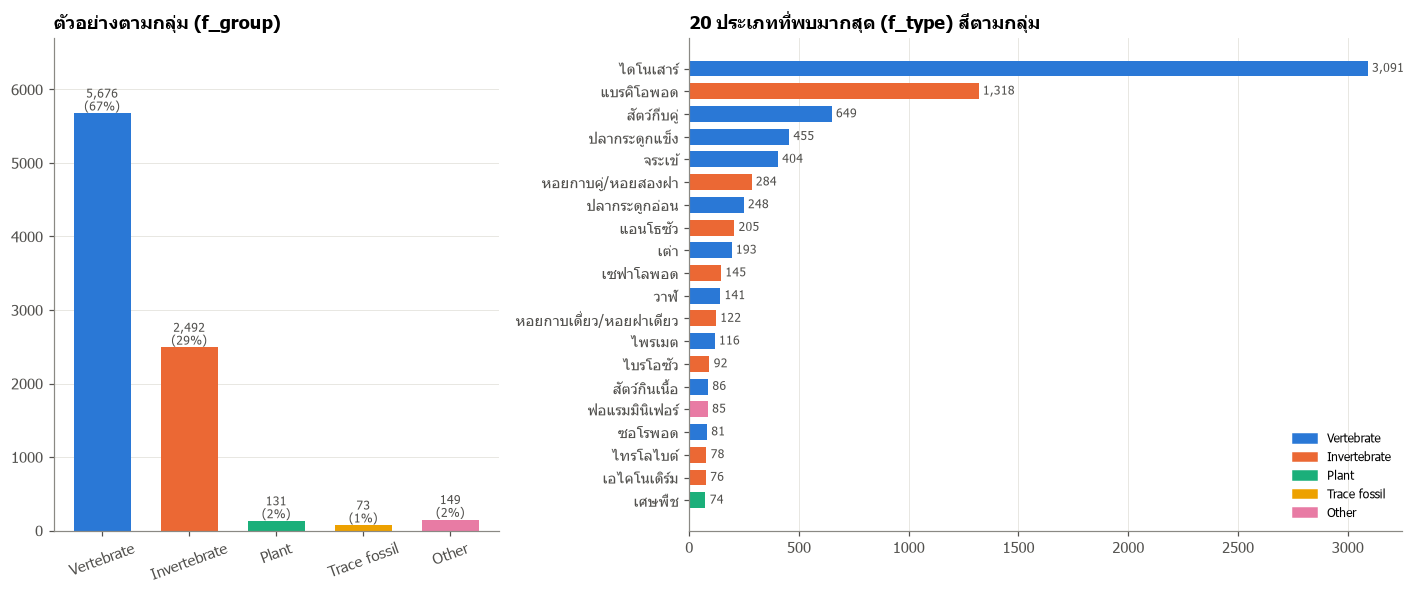

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})

g = fl.f_group.value_counts().reindex(GROUP_ORDER).dropna()
axes[0].bar(g.index, g.values, color=[GROUP_COLOR[k] for k in g.index], width=0.65)
for x, v in enumerate(g.values):
    axes[0].text(x, v, f"{v:,.0f}\n({v / len(fl):.0%})", ha="center", va="bottom", fontsize=8, color="#52514e")
axes[0].set_title("ตัวอย่างตามกลุ่ม (f_group)")
axes[0].set_ylim(0, g.max() * 1.18)
axes[0].grid(axis="x", visible=False)
axes[0].tick_params(axis="x", rotation=20)

top_type = fl.groupby("f_type", observed=True).agg(n=("fossil_id", "size"), group=("f_group", lambda s: s.mode().iat[0])).nlargest(20, "n")
tt = top_type[::-1]
axes[1].barh(tt.index, tt.n, color=[GROUP_COLOR[k] for k in tt.group], height=0.7)
for y, v in enumerate(tt.n):
    axes[1].text(v + 20, y, f"{v:,}", va="center", fontsize=8, color="#52514e")
axes[1].set_title("20 ประเภทที่พบมากสุด (f_type) สีตามกลุ่ม")
axes[1].grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[k]) for k in GROUP_ORDER]
axes[1].legend(handles, GROUP_ORDER, loc="lower right", frameon=False, fontsize=8)
plt.tight_layout()

ตัวอย่างกระดูกสันหลัง (Vertebrate) คิดเป็นราวสองในสาม และไดโนเสาร์เป็นประเภทที่มากที่สุด
สะท้อนว่าทะเบียนนี้เน้นงานขุดค้นไดโนเสาร์ในภาคอีสาน (หมวดหินเสาขัว / ภูกระดึง)

### 2.3 ระดับการจำแนกทางอนุกรมวิธาน

id_level,species,genus,higher/informal,unidentified
f_group,,,,
Vertebrate,40.9,4.4,11.2,43.5
Invertebrate,18.2,32.1,3.2,46.5
Plant,18.3,12.2,0.0,69.5
Trace fossil,0.0,67.1,6.8,26.0
Other,11.4,15.4,27.5,45.6
All,33.0,13.4,9.0,44.7


จำแนกถึงสกุลหรือชนิดได้ 46.4% ของตัวอย่างทั้งหมด (ถึงชนิด 33.0%)
ตัวอย่างชื่อในแต่ละระดับ:
  species:  Phuwiangosaurus sirindhornae, Balaenoptera edeni, Thaiichthys buddhabutrensis, Siamosuchus phuphokensis, Rusa unicolor
  genus:  Linoproductus sp., cf. Asianopodus isp., Glyphis sp., Stenoscisma sp., Posidonomya sp.
  higher/informal:  Sauropod, Fusulinida indet., Theropod, Nautiloidea indet., Phytosaur


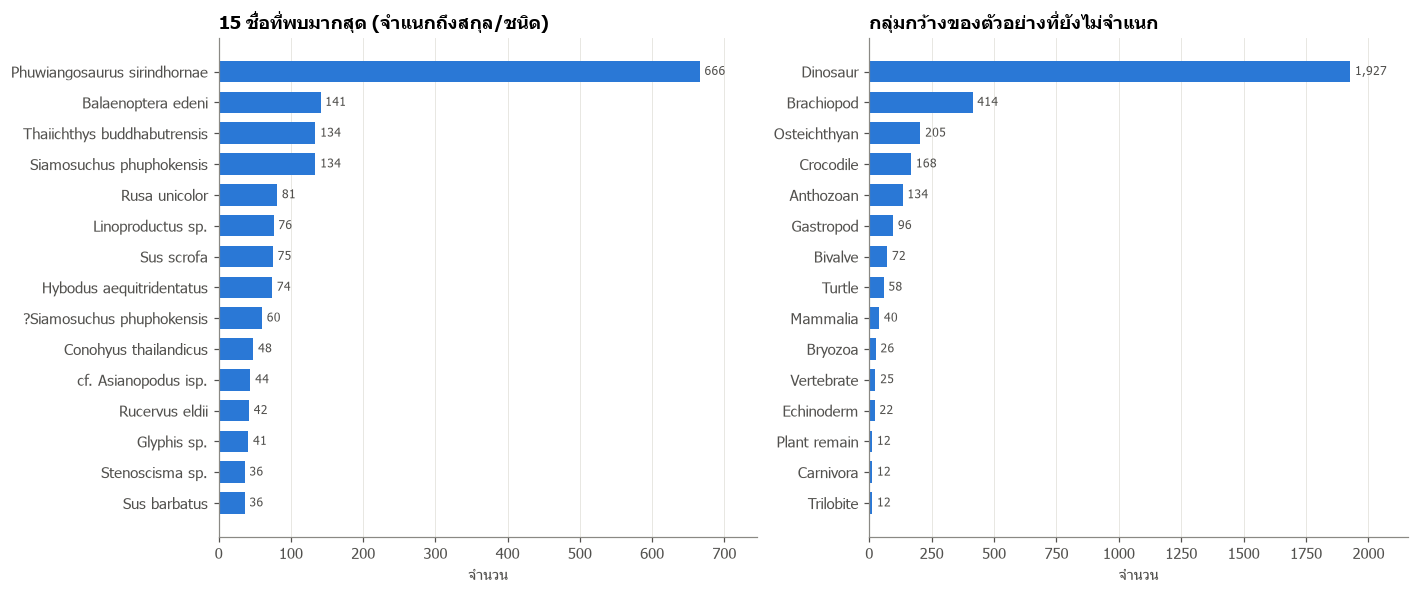

In [8]:
share = pd.crosstab(fl.f_group, fl.id_level, normalize="index", margins=True).mul(100).round(1)
display(share)
print(f"จำแนกถึงสกุลหรือชนิดได้ {fl.identified.mean():.1%} ของตัวอย่างทั้งหมด (ถึงชนิด {fl.id_level.eq('species').mean():.1%})")
print("ตัวอย่างชื่อในแต่ละระดับ:")
for lv in ID_LEVELS[:3]:
    print(f"  {lv}: ", ", ".join(fl.loc[fl.id_level.eq(lv), "sci_name"].value_counts().head(5).index))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
barh(axes[0], fl.loc[fl.identified, "sci_name"].value_counts().head(15), "15 ชื่อที่พบมากสุด (จำแนกถึงสกุล/ชนิด)")
barh(axes[1], fl.broad_taxon.value_counts().head(15), "กลุ่มกว้างของตัวอย่างที่ยังไม่จำแนก")
plt.tight_layout()

### 2.4 เจาะลึกไดโนเสาร์

ตัวอย่างไดโนเสาร์ 3,176 ชิ้น (37%) | จำแนกถึงสกุล/ชนิด 25%


id_level,unidentified,species,higher/informal,genus
n,1927,798,448,3


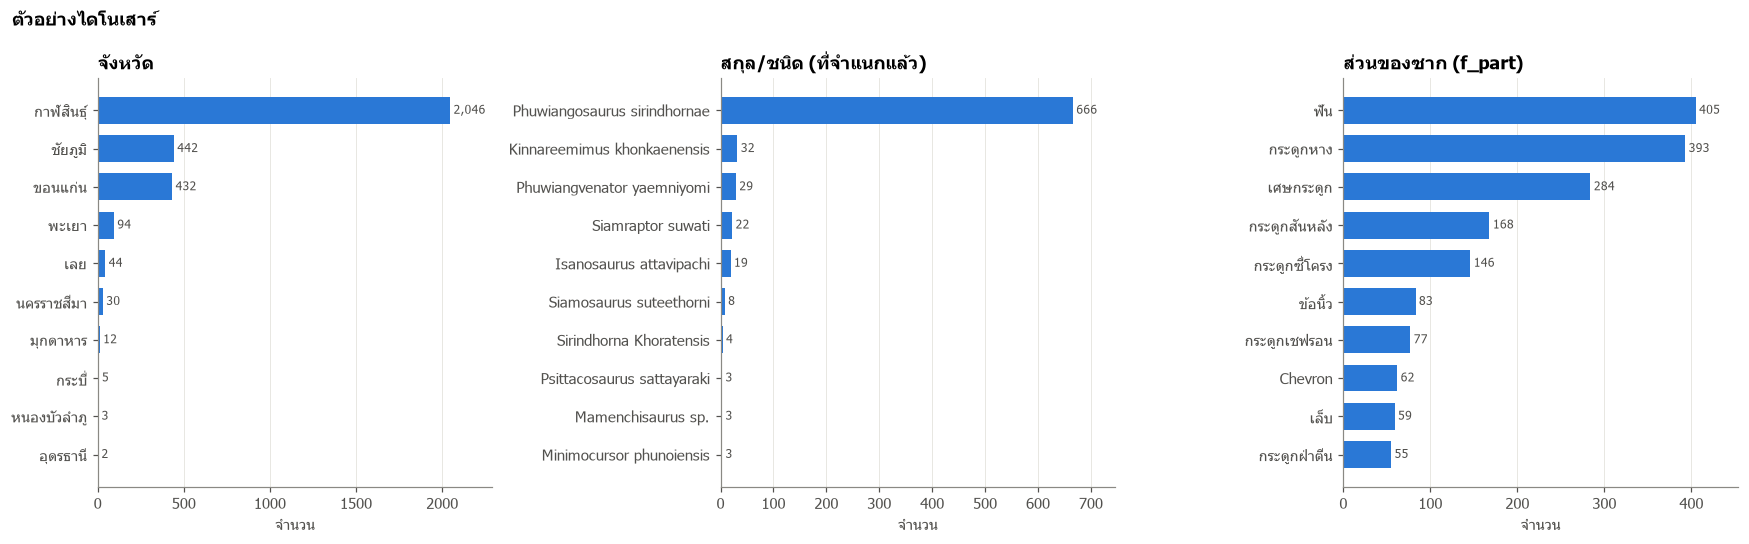

In [9]:
dino = fl[fl.f_type.eq("ไดโนเสาร์") | fl.com_name.isin(["ไดโนเสาร์", "ซอโรพอด", "เทอโรพอด"]) | fl.broad_taxon.eq("Dinosaur")]
print(f"ตัวอย่างไดโนเสาร์ {len(dino):,} ชิ้น ({len(dino) / len(fl):.0%}) | จำแนกถึงสกุล/ชนิด {dino.identified.mean():.0%}")
display(dino.id_level.value_counts().to_frame("n").T)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
barh(axes[0], dino.province.value_counts().head(10), "จังหวัด")
barh(axes[1], dino.loc[dino.identified, "sci_name"].value_counts().head(10), "สกุล/ชนิด (ที่จำแนกแล้ว)")
barh(axes[2], dino.f_part.value_counts().head(10), "ส่วนของซาก (f_part)")
fig.suptitle("ตัวอย่างไดโนเสาร์", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### 2.5 ส่วนของซากและผู้ค้นพบ

f_part มี 991 ค่า (เขียนอิสระ ผสมไทย/อังกฤษ) | dis_name มี 326 ค่า และหายไป 30%


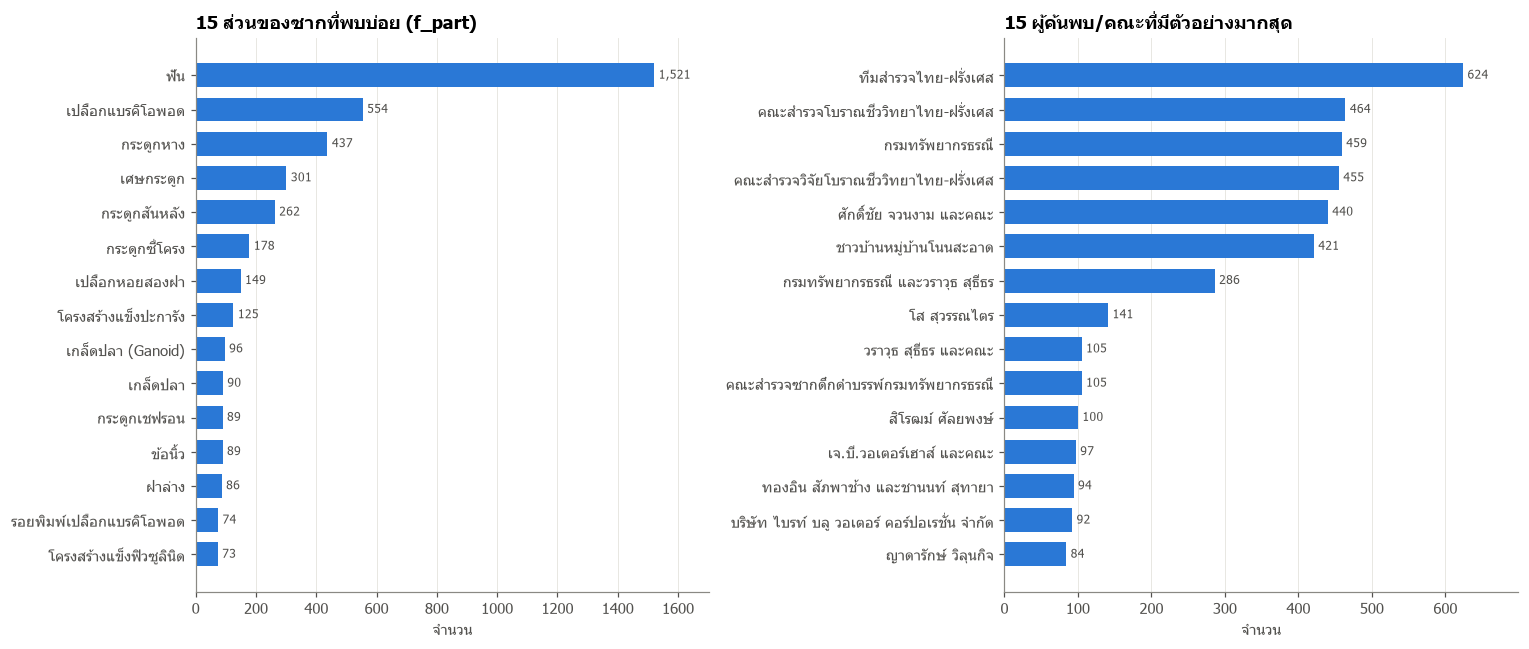

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
barh(axes[0], fl.f_part.value_counts().head(15), "15 ส่วนของซากที่พบบ่อย (f_part)")
barh(axes[1], fl.dis_name.value_counts().head(15).rename(lambda s: s if len(s) <= 45 else s[:44] + "…"), "15 ผู้ค้นพบ/คณะที่มีตัวอย่างมากสุด")
plt.tight_layout()
print(f"f_part มี {fl.f_part.nunique():,} ค่า (เขียนอิสระ ผสมไทย/อังกฤษ) | dis_name มี {fl.dis_name.nunique()} ค่า และหายไป {fl.dis_name.isna().mean():.0%}")

`dis_name` มีชื่อคณะเดียวกันที่เขียนต่างกัน เช่น "ทีมสำรวจไทย-ฝรั่งเศส", "คณะสำรวจโบราณชีววิทยาไทย-ฝรั่งเศส"
และ "คณะสำรวจวิจัยโบราณชีววิทยาไทย-ฝรั่งเศส" ถ้าจะวิเคราะห์ตามผู้ค้นพบต้องจัดกลุ่มชื่อก่อน

### 2.6 การกระจายตามพื้นที่

มีจังหวัดระบุ 97.8% | 3 จังหวัดแรกรวมกัน 54% ของตัวอย่างที่ระบุจังหวัด


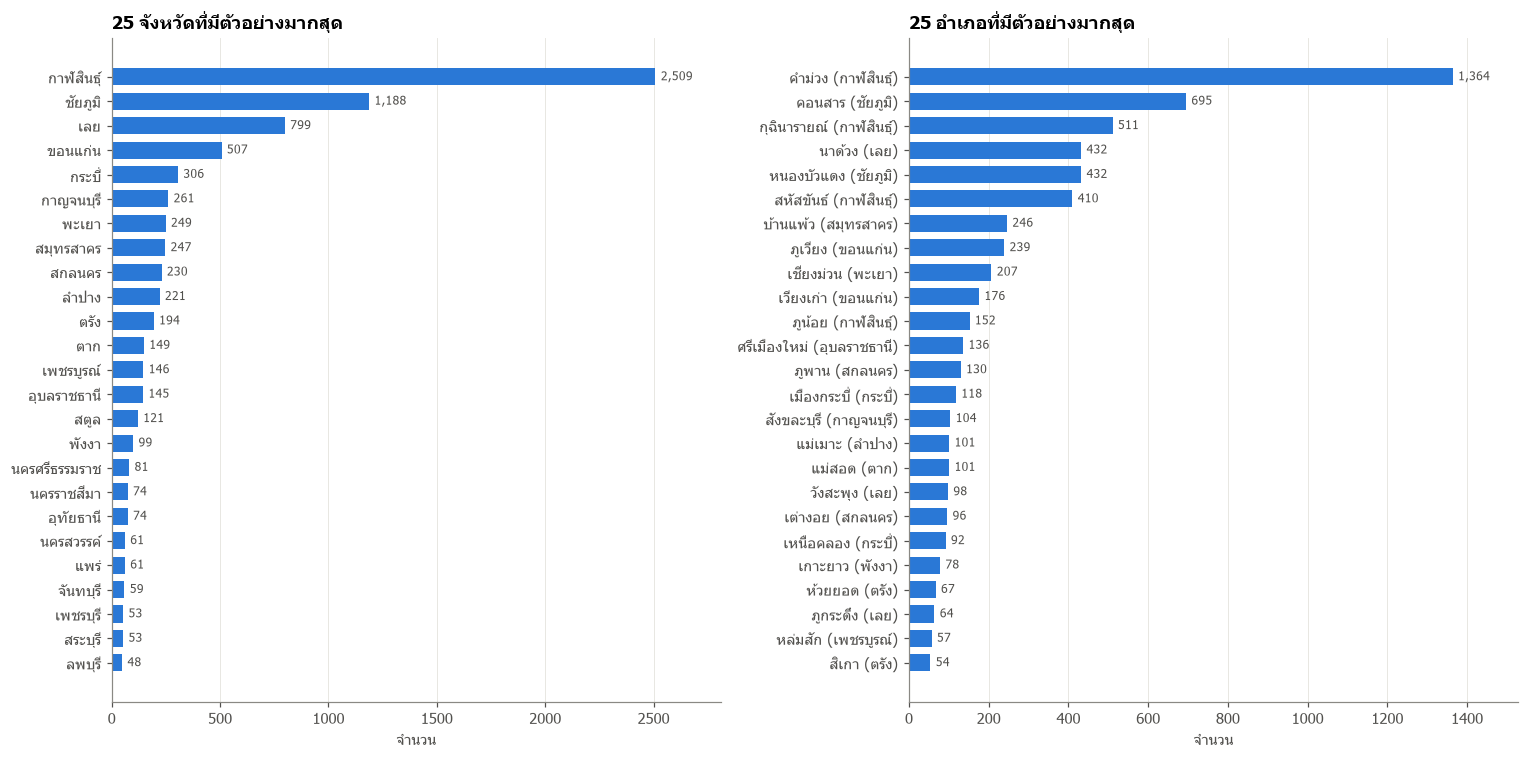

In [11]:
prov = fl.province.value_counts()
top3 = prov.head(3).sum() / prov.sum()
print(f"มีจังหวัดระบุ {fl.province.notna().mean():.1%} | 3 จังหวัดแรกรวมกัน {top3:.0%} ของตัวอย่างที่ระบุจังหวัด")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
barh(axes[0], prov.head(25), "25 จังหวัดที่มีตัวอย่างมากสุด")
loc = (fl.dropna(subset=["district"]).assign(place=lambda d: d.district + " (" + d.province.fillna("?") + ")")["place"].value_counts().head(25))
barh(axes[1], loc, "25 อำเภอที่มีตัวอย่างมากสุด")
plt.tight_layout()

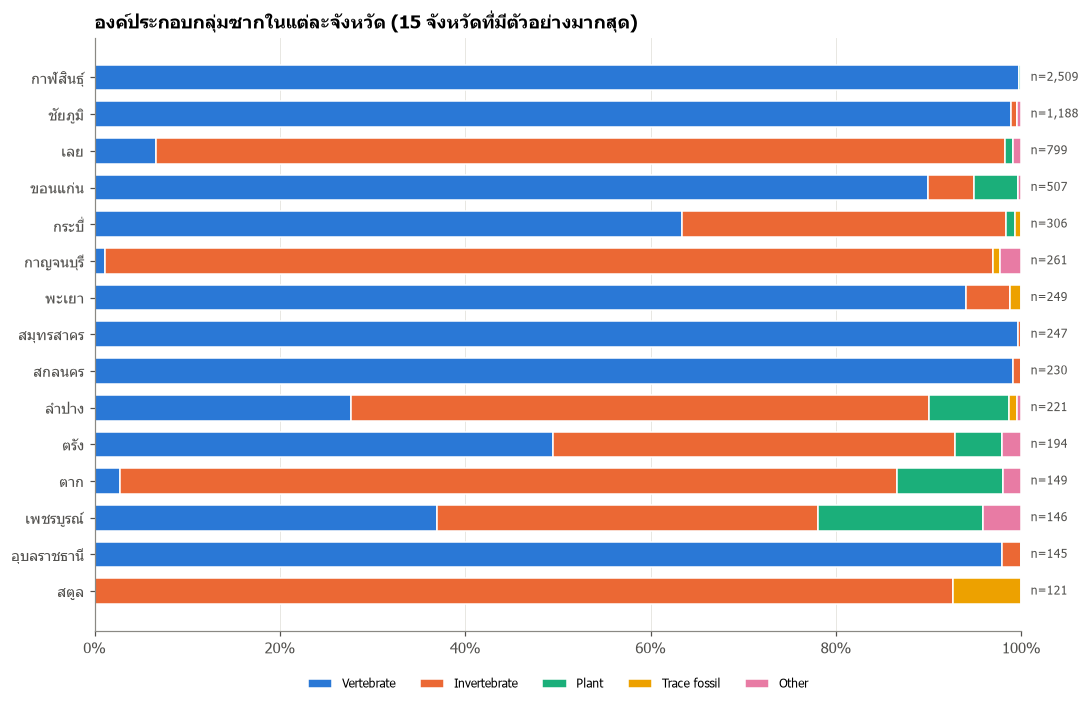

In [12]:
# จังหวัด × กลุ่ม: สัดส่วนในแต่ละจังหวัด (15 จังหวัดแรก)
ct = pd.crosstab(fl.province, fl.f_group).reindex(prov.head(15).index)[GROUP_ORDER]
pct = ct.div(ct.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 6.5))
left = np.zeros(len(pct))
for gname in GROUP_ORDER:
    ax.barh(pct.index[::-1], pct[gname].values[::-1], left=left[::-1], color=GROUP_COLOR[gname], label=gname,
            height=0.7, edgecolor="white", linewidth=1)
    left += pct[gname].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("องค์ประกอบกลุ่มซากในแต่ละจังหวัด (15 จังหวัดที่มีตัวอย่างมากสุด)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False, fontsize=8)
for y, n in enumerate(ct.sum(axis=1).values[::-1]):
    ax.text(1.01, y, f"n={n:,}", va="center", fontsize=8, color="#52514e", transform=ax.get_yaxis_transform())
plt.tight_layout()

### 2.7 ช่วงเวลาที่บันทึกเข้าฐานข้อมูล

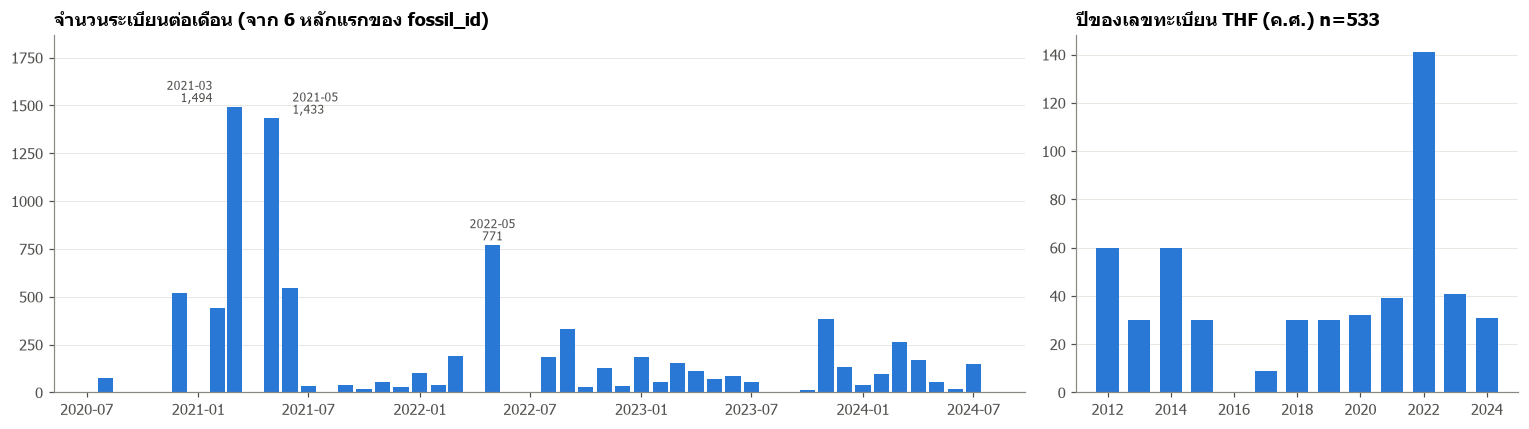

In [13]:
monthly = fl.set_index("record_month").resample("MS").size()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(monthly.index, monthly.values, width=25, color=BAR)
axes[0].set_title("จำนวนระเบียนต่อเดือน (จาก 6 หลักแรกของ fossil_id)")
axes[0].grid(axis="x", visible=False)
for j, (d, v) in enumerate(monthly.nlargest(3).sort_index().items()):
    dx = (-14, 14, 0)[j] if j < 2 else 0
    axes[0].annotate(f"{d:%Y-%m}\n{v:,}", (d, v), textcoords="offset points", xytext=(dx, 3),
                     ha="right" if dx < 0 else "left" if dx > 0 else "center", fontsize=8, color="#52514e")
axes[0].set_ylim(0, monthly.max() * 1.25)

ry = fl.regis_year_ce.value_counts().sort_index()
axes[1].bar(ry.index.astype(int), ry.values, color=BAR, width=0.7)
axes[1].set_title(f"ปีของเลขทะเบียน THF (ค.ศ.) n={ry.sum()}")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()

การบันทึกเป็นช่วง ๆ (เดือนเดียวอาจมีหลายพันระเบียน) จึงสะท้อน**รอบการนำเข้าข้อมูล** ไม่ใช่วันที่ขุดพบจริง
ห้ามใช้เป็นเวลาที่ค้นพบ

## 3. โหลดและทำความสะอาดแหล่งซากดึกดำบรรพ์

- `FOS_GR_1`..`FOS_GR_5` เป็น**แฟล็ก**ของ 5 กลุ่ม (Vertebrate / Invertebrate / Plant / Trace / Other) โดย `N` = ไม่พบ จึงแปลงเป็น boolean
- คอลัมน์ที่ว่างทั้งหมด เช่น `DIS_YEAR`, `PERIODTO`, `POTENTIAL*`, `STATUS` จะตัดออก
- `PERIODFROM` สะกดได้หลายแบบ เช่น จูแรสสิก / จูแรสซิก / จูราสซิก และ ครีเทเชียส / ครีเทเซียส จึงจับคำสำคัญด้วย regex แล้วแปลงเป็นยุคมาตรฐาน (เก่าสุด–อ่อนสุด)

In [14]:
PERIODS = ["Precambrian", "Cambrian", "Ordovician", "Silurian", "Devonian", "Carboniferous", "Permian",
           "Triassic", "Jurassic", "Cretaceous", "Tertiary", "Quaternary"]
P_RANK = {p: i for i, p in enumerate(PERIODS)}
PERIOD_TH = {
    "Cambrian": r"แคมเบรียน", "Ordovician": r"ออร์โด", "Silurian": r"ไซลูเรียน", "Devonian": r"ดีโวเนียน",
    "Carboniferous": r"คาร์บอนิเฟอรัส", "Permian": r"เพอร์เมียน", "Triassic": r"ไทรแอส", "Jurassic": r"จู(?:แร|รา)ส",
    "Cretaceous": r"ครีเท", "Tertiary": r"เทอร์เชียรี|นีโอจีน|พาลีโอจีน|ไมโอซีน|ไพลโอซีน|โอลิโกซีน|อีโอซีน",
    "Quaternary": r"ควอเทอร์นารี|ไพลสโตซีน|โฮโลซีน",
}


def parse_period_th(text):
    # คืน (ยุคเก่าสุด, ยุคอ่อนสุด) จากข้อความภาษาไทยอิสระ
    if not isinstance(text, str) or not text:
        return (pd.NA, pd.NA)
    found = [p for p, pat in PERIOD_TH.items() if re.search(pat, text)]
    if not found:
        return (pd.NA, pd.NA)
    found.sort(key=P_RANK.get)
    return (found[0], found[-1])


GR_FLAGS = {"FOS_GR_1": "Vertebrate", "FOS_GR_2": "Invertebrate", "FOS_GR_3": "Plant", "FOS_GR_4": "Trace fossil", "FOS_GR_5": "Other"}

sites_raw = gpd.read_file(SITES)
sites = sites_raw.copy()
str_cols = [c for c in sites.columns if c != "geometry" and sites[c].dtype == object or str(sites[c].dtype) == "str"]
for c in str_cols:
    sites[c] = sites[c].map(clean_th).replace({"": pd.NA, "<Null>": pd.NA})

empty_cols = [c for c in sites.columns if c != "geometry" and sites[c].isna().all()]
sites = sites.drop(columns=empty_cols)
print("ตัดคอลัมน์ว่างทั้งหมด:", empty_cols)

for col, gname in GR_FLAGS.items():
    sites[gname] = sites[col].notna() & sites[col].ne("N")
sites["n_groups"] = sites[list(GR_FLAGS.values())].sum(axis=1)
sites["primary_group"] = sites[list(GR_FLAGS.values())].idxmax(axis=1).where(sites.n_groups > 0)

periods = sites.PERIODFROM.map(parse_period_th)
sites["period_old"] = [p[0] for p in periods]
sites["period_young"] = [p[1] for p in periods]
sites["is_dinosaur"] = sites[["NAME_TH", "FOS_DES_TH"]].fillna("").agg(" ".join, axis=1).str.contains("ไดโนเสาร์")
sites["importance"] = sites.IMPORTA_TH.str.rstrip("*")
sites["district_key"] = [norm_district(p, d) for p, d in zip(sites.PROVINCE, sites.DISTRICT)]

print(f"{len(sites)} แหล่ง | {sites.PROVINCE.nunique()} จังหวัด | CRS {sites.crs}")
pd.crosstab(sites.PERIODFROM.fillna("(ว่าง)"), sites.period_old.fillna("(แปลงไม่ได้)")).loc[lambda t: t.index != "(ว่าง)"]

ตัดคอลัมน์ว่างทั้งหมด: ['NAME_ENG', 'FEATURE_EN', 'GEO_DES_EN', 'PERIODTO', 'DIS_BY_ENG', 'DIS_BY_TH', 'DIS_DAY', 'DIS_MONTH', 'DIS_YEAR', 'OWNER_ENG', 'POTENTIAL1', 'POTENTIAL2', 'POTENTIAL3', 'POTENTIAL4', 'POTENTIAL5', 'POTENTIAL6', 'POTENTIAL7', 'STATUS']
518 แหล่ง | 39 จังหวัด | CRS EPSG:4326


period_old,(แปลงไม่ได้),Cambrian,Carboniferous,Cretaceous,Devonian,Jurassic,Ordovician,Permian,Quaternary,Triassic
PERIODFROM,,,,,,,,,,
ครีเทเชียส,0,0,0,2,0,0,0,0,0,0
ครีเทเชียสตอนต้น,0,0,0,4,0,0,0,0,0,0
ครีเทเซียส,0,0,0,1,0,0,0,0,0,0
ครีเทเซียสตอนต้น,0,0,0,4,0,0,0,0,0,0
ควอเทอร์นารี,0,0,0,0,0,0,0,0,3,0
คาร์บอนิเฟอรัส,0,0,17,0,0,0,0,0,0,0
จูราสซิกตอนกลาง-ตอนปลาย,0,0,0,0,0,1,0,0,0,0
จูแรสซิก,0,0,0,0,0,3,0,0,0,0
จูแรสสิก,0,0,0,0,0,2,0,0,0,0


In [15]:
key_cols = ["NAME_TH", "NAME_ENG", "IMPORTA_TH", "LOCALITY", "TAMBON", "DISTRICT", "PROVINCE", "GEO_GROUP", "FORMATION",
            "PERIODFROM", "FOS_DES_TH", "GEO_DES_TH", "DIS_BY_ENG", "OWNER_TH"]
missing_table(sites, [c for c in key_cols if c in sites.columns])

,non_null,missing,missing_%,unique
NAME_TH,518,0,0.0,517
IMPORTA_TH,518,0,0.0,5
LOCALITY,264,254,49.0,226
TAMBON,518,0,0.0,270
DISTRICT,518,0,0.0,151
PROVINCE,518,0,0.0,39
GEO_GROUP,177,341,65.8,14
FORMATION,172,346,66.8,51
PERIODFROM,166,352,68.0,27
FOS_DES_TH,504,14,2.7,390


## 4. EDA แหล่งซากดึกดำบรรพ์

### 4.1 จังหวัด สถานะ และผู้ดูแลพื้นที่

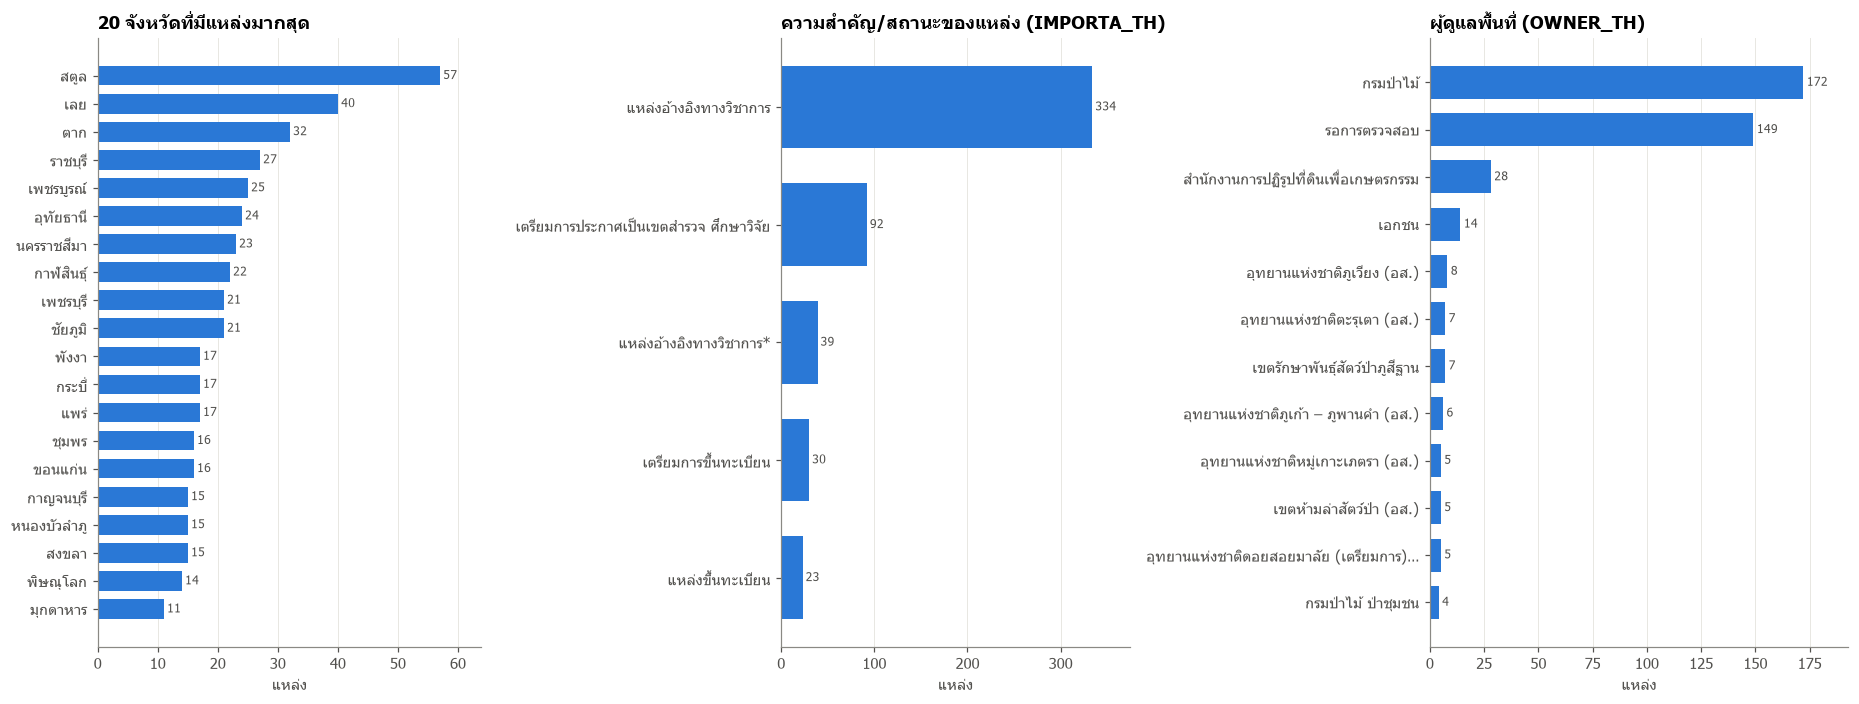

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.1, 1, 1.2]})
barh(axes[0], sites.PROVINCE.value_counts().head(20), "20 จังหวัดที่มีแหล่งมากสุด", xlabel="แหล่ง")
barh(axes[1], sites.IMPORTA_TH.value_counts(), "ความสำคัญ/สถานะของแหล่ง (IMPORTA_TH)", xlabel="แหล่ง")
barh(axes[2], sites.OWNER_TH.value_counts().head(12).rename(lambda s: s if len(s) <= 38 else s[:37] + "…"), "ผู้ดูแลพื้นที่ (OWNER_TH)", xlabel="แหล่ง")
plt.tight_layout()

มีแหล่งที่**ขึ้นทะเบียนแล้ว**เพียง 23 แห่ง ส่วนใหญ่เป็น "แหล่งอ้างอิงทางวิชาการ" และกว่า 1 ใน 4
ยังไม่ทราบผู้ดูแลพื้นที่ (`รอการตรวจสอบ`) ที่มีผู้ดูแลส่วนใหญ่อยู่ในเขตกรมป่าไม้/อุทยาน (อส.)

### 4.2 กลุ่มซากที่พบในแต่ละแหล่ง

แหล่งที่เกี่ยวกับไดโนเสาร์ (จากชื่อ/คำบรรยาย): 79


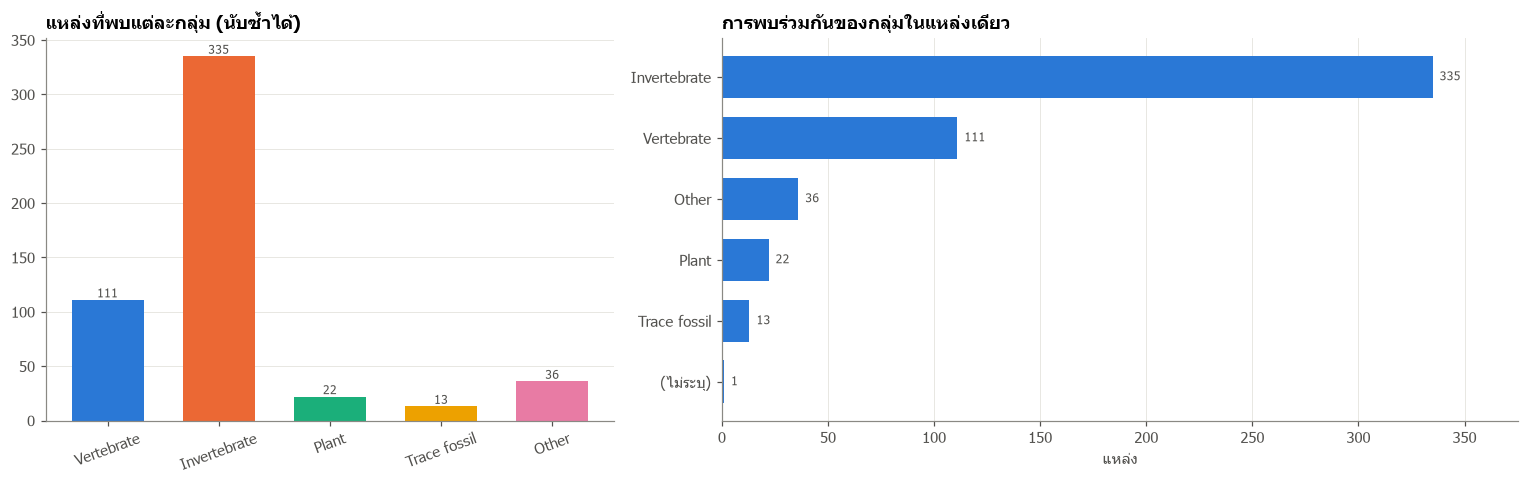

In [17]:
flag_counts = sites[list(GR_FLAGS.values())].sum().reindex(GROUP_ORDER)
combo = sites[list(GR_FLAGS.values())].apply(lambda r: " + ".join(k for k, v in r.items() if v) or "(ไม่ระบุ)", axis=1).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].bar(flag_counts.index, flag_counts.values, color=[GROUP_COLOR[k] for k in flag_counts.index], width=0.65)
for x, v in enumerate(flag_counts.values):
    axes[0].text(x, v, f"{v}", ha="center", va="bottom", fontsize=8, color="#52514e")
axes[0].set_title("แหล่งที่พบแต่ละกลุ่ม (นับซ้ำได้)")
axes[0].grid(axis="x", visible=False)
axes[0].tick_params(axis="x", rotation=20)
barh(axes[1], combo.head(10), "การพบร่วมกันของกลุ่มในแหล่งเดียว", xlabel="แหล่ง")
plt.tight_layout()
print(f"แหล่งที่เกี่ยวกับไดโนเสาร์ (จากชื่อ/คำบรรยาย): {sites.is_dinosaur.sum()}")

### 4.3 อายุทางธรณีวิทยาและหน่วยหินที่บันทึกไว้

ไม่มีข้อมูลยุค 68% | ไม่มีหมวดหิน 67% | ไม่มีกลุ่มหิน 66%


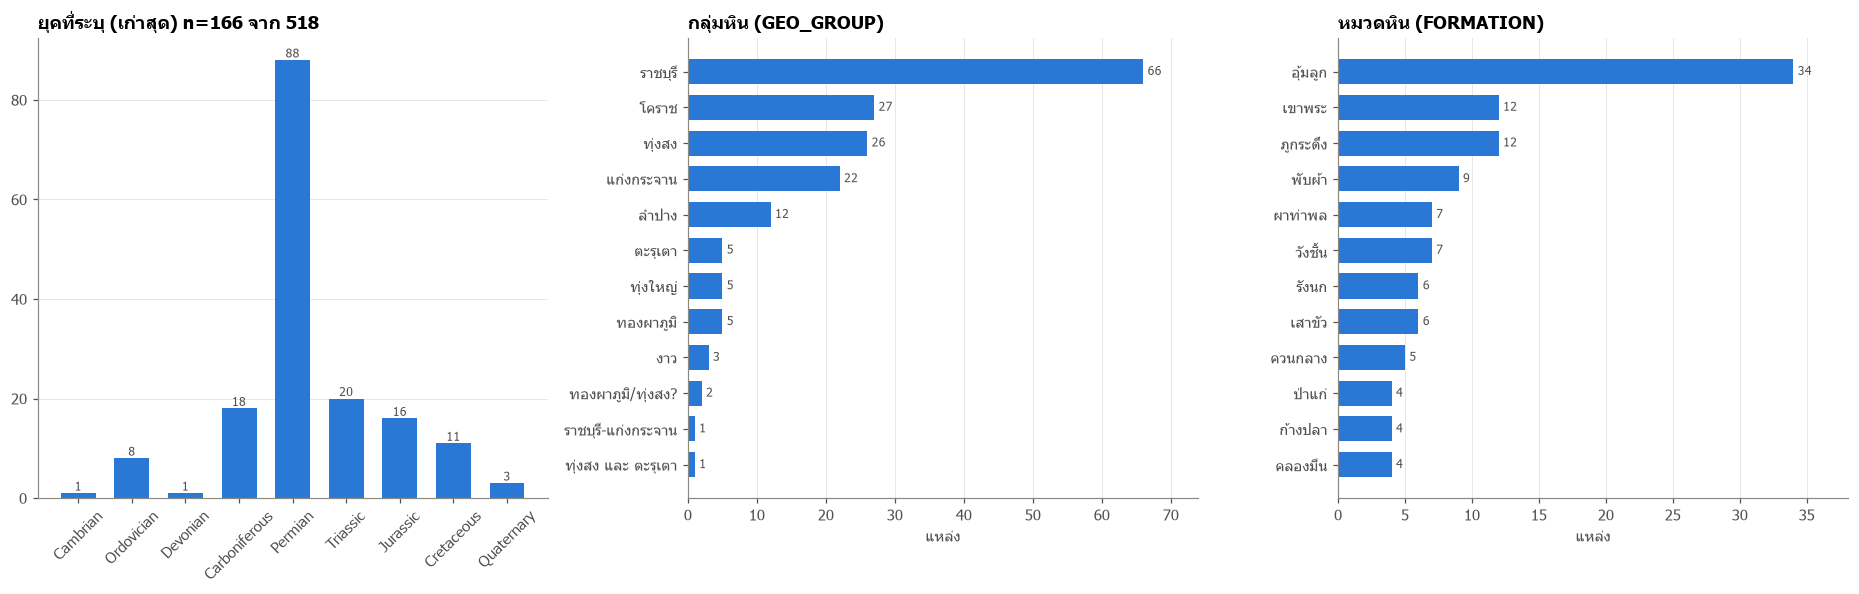

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
po = sites.period_old.value_counts().reindex([p for p in PERIODS if p in set(sites.period_old.dropna())])
axes[0].bar(po.index, po.values, color=BAR, width=0.65)
for x, v in enumerate(po.values):
    axes[0].text(x, v, f"{v}", ha="center", va="bottom", fontsize=8, color="#52514e")
axes[0].set_title(f"ยุคที่ระบุ (เก่าสุด) n={po.sum()} จาก {len(sites)}")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="x", visible=False)
barh(axes[1], sites.GEO_GROUP.value_counts().head(12), "กลุ่มหิน (GEO_GROUP)", xlabel="แหล่ง")
barh(axes[2], sites.FORMATION.value_counts().head(12), "หมวดหิน (FORMATION)", xlabel="แหล่ง")
plt.tight_layout()
print(f"ไม่มีข้อมูลยุค {sites.period_old.isna().mean():.0%} | ไม่มีหมวดหิน {sites.FORMATION.isna().mean():.0%} | ไม่มีกลุ่มหิน {sites.GEO_GROUP.isna().mean():.0%}")

มีแหล่งที่บันทึกยุคไว้ไม่ถึงหนึ่งในสาม ในส่วนที่ 5 จะเติมช่องว่างนี้ด้วยการ**ซ้อนตำแหน่งแหล่งกับแผนที่หน่วยหิน**

### 4.4 แผนที่แหล่งซากดึกดำบรรพ์

หน่วยหิน 7,093 polygon | 94 สัญลักษณ์


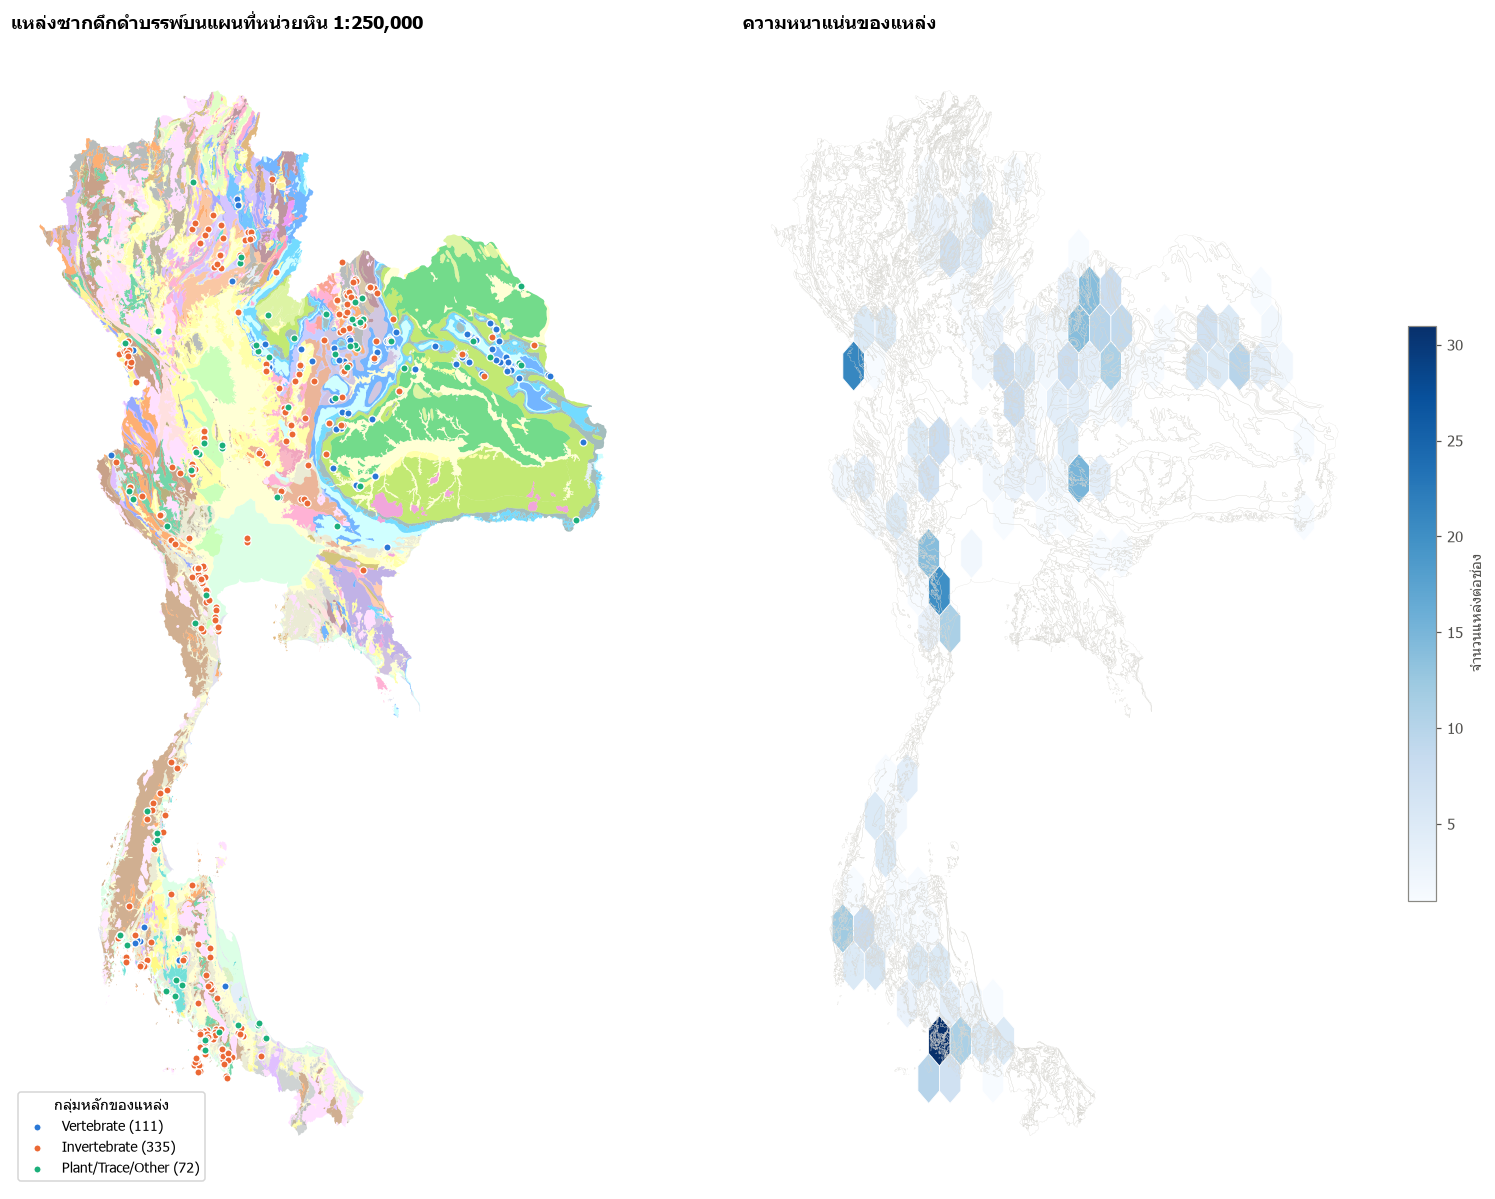

In [19]:
legend = pd.read_csv(ROCK_LEGEND, encoding="utf-8-sig")
legend.loc[legend.TEXT_SYM.eq("Water body"), "color_hex"] = "#cfe3f3"
rock = gpd.read_file(ROCK_UNITS)[["OBJECTID", "TEXT_SYM", "geometry"]].merge(legend, on="TEXT_SYM", how="left")
print(f"หน่วยหิน {len(rock):,} polygon | {rock.TEXT_SYM.nunique()} สัญลักษณ์")

# แผนที่ไม่เกิน 3 สี (สีเยอะกว่านี้แยกกันยากบนจุดที่กระจาย): Vertebrate / Invertebrate / อื่น ๆ
MAP_CLASS = {"Vertebrate": "Vertebrate", "Invertebrate": "Invertebrate"}
sites["map_class"] = sites.primary_group.map(MAP_CLASS).fillna("Plant/Trace/Other")
MAP_COLOR = {"Vertebrate": GROUP_COLOR["Vertebrate"], "Invertebrate": GROUP_COLOR["Invertebrate"], "Plant/Trace/Other": GROUP_COLOR["Plant"]}

fig, axes = plt.subplots(1, 2, figsize=(15, 11))
rock.plot(ax=axes[0], color=rock.color_hex.fillna("#dddddd"), linewidth=0, alpha=0.55)
for ax in axes:
    ax.set_axis_off()
for cls, col in MAP_COLOR.items():
    s = sites[sites.map_class.eq(cls)]
    s.plot(ax=axes[0], color=col, markersize=22, edgecolor="white", linewidth=0.8, label=f"{cls} ({len(s)})")
axes[0].legend(loc="lower left", frameon=True, fontsize=9, title="กลุ่มหลักของแหล่ง")
axes[0].set_title("แหล่งซากดึกดำบรรพ์บนแผนที่หน่วยหิน 1:250,000")

rock.boundary.plot(ax=axes[1], color="#d9d8d3", linewidth=0.15)
hb = axes[1].hexbin(sites.geometry.x, sites.geometry.y, gridsize=22, mincnt=1, cmap="Blues", edgecolors="white", linewidths=0.5)
fig.colorbar(hb, ax=axes[1], shrink=0.5, label="จำนวนแหล่งต่อช่อง")
axes[1].set_title("ความหนาแน่นของแหล่ง")
plt.tight_layout()

แผนที่แบบโต้ตอบ (ซูม/คลิกดูรายละเอียดแต่ละแหล่งได้ ต้องต่ออินเทอร์เน็ตเพื่อโหลดแผนที่พื้นหลัง)

In [20]:
m = folium.Map(location=[13.5, 101], zoom_start=6, tiles="OpenStreetMap")
for _, r in sites.iterrows():
    groups = ", ".join(g for g in GR_FLAGS.values() if r[g]) or "-"
    html = (f"<b>{r.NAME_TH}</b><br>{r.DISTRICT or ''} {r.PROVINCE or ''}<br>"
            f"<i>{groups}</i><br>{r.FOS_DES_TH or ''}<br>ยุค: {r.PERIODFROM or '-'} | หมวดหิน: {r.FORMATION or '-'}<br>"
            f"สถานะ: {r.IMPORTA_TH}")
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=5, color="white", weight=1, fill=True, fill_opacity=0.9,
                        fill_color=MAP_COLOR[r.map_class], tooltip=r.NAME_TH, popup=folium.Popup(html, max_width=320)).add_to(m)
m

## 5. บริบทธรณีวิทยา: แหล่งซากดึกดำบรรพ์ × แผนที่หน่วยหิน

แผนที่หน่วยหินมีแค่สัญลักษณ์ (`TEXT_SYM` เช่น `Pr`, `Jpk`, `Trgr`) ตัวอักษรนำหน้าบอกยุค เช่น
`Q` ควอเทอร์นารี, `T` เทอร์เชียรี, `K` ครีเทเชียส, `J` จูแรสซิก, `Tr` ไทรแอสซิก, `P` เพอร์เมียน, `C` คาร์บอนิเฟอรัส,
`D` ดีโวเนียน, `S` ไซลูเรียน, `O` ออร์โดวิเชียน, `E` (Ꞓ) แคมเบรียน, `PE` พรีแคมเบรียน
ถ้าเป็นช่วงจะเขียนต่อกัน เช่น `JK` หรือ `PTr` ส่วนหน่วยในท้าย legend (ลำดับตั้งแต่ `Qgy` ลงไป) เป็นหินอัคนี/หินภูเขาไฟ

In [21]:
PREFIX = {"PE": ("Precambrian", "Precambrian"), "EO": ("Cambrian", "Ordovician"), "E": ("Cambrian", "Cambrian"),
          "O": ("Ordovician", "Ordovician"), "SDC": ("Silurian", "Carboniferous"), "SD": ("Silurian", "Devonian"),
          "DC": ("Devonian", "Carboniferous"), "D": ("Devonian", "Devonian"), "CP": ("Carboniferous", "Permian"),
          "C": ("Carboniferous", "Carboniferous"), "PTr": ("Permian", "Triassic"), "P": ("Permian", "Permian"),
          "TrJ": ("Triassic", "Jurassic"), "Tr": ("Triassic", "Triassic"), "JK": ("Jurassic", "Cretaceous"),
          "J": ("Jurassic", "Jurassic"), "KT": ("Cretaceous", "Tertiary"), "K": ("Cretaceous", "Cretaceous"),
          "T": ("Tertiary", "Tertiary"), "Q": ("Quaternary", "Quaternary")}


def symbol_period(sym):
    for p in sorted(PREFIX, key=len, reverse=True):
        if isinstance(sym, str) and sym.startswith(p):
            return PREFIX[p]
    return (pd.NA, pd.NA)


igneous_from = legend.loc[legend.TEXT_SYM.eq("Qgy"), "order"].iat[0]
legend["rock_kind"] = np.where(legend.TEXT_SYM.eq("Water body"), "water", np.where(legend.order >= igneous_from, "igneous", "sedimentary/metamorphic"))
legend[["map_period_old", "map_period_young"]] = legend.TEXT_SYM.map(symbol_period).tolist()
legend["unit_label"] = (legend.TEXT_SYM + " " + legend.label_th.fillna("")).str.strip()

rock = rock.drop(columns=[c for c in ["rock_kind", "map_period_old", "map_period_young", "unit_label"] if c in rock]).merge(
    legend[["TEXT_SYM", "rock_kind", "map_period_old", "map_period_young", "unit_label"]], on="TEXT_SYM", how="left")

sj = gpd.sjoin(sites[["OBJECTID", "geometry"]], rock[["TEXT_SYM", "unit_label", "rock_kind", "map_period_old", "map_period_young", "geometry"]],
               how="left", predicate="within").drop(columns="index_right").drop_duplicates("OBJECTID")
sites = sites.drop(columns=[c for c in sj.columns if c in sites.columns and c not in ("OBJECTID", "geometry")]).merge(sj.drop(columns="geometry"), on="OBJECTID", how="left")
print(f"แหล่งที่ตกอยู่ใน polygon หน่วยหิน: {sites.TEXT_SYM.notna().sum()}/{len(sites)}")
sites.TEXT_SYM.isna().pipe(lambda m: sites.loc[m, ["NAME_TH", "PROVINCE"]]).head()

แหล่งที่ตกอยู่ใน polygon หน่วยหิน: 500/518


,NAME_TH,PROVINCE
21,ไทรโลไบต์เกาะยาว,สตูล
24,แบรคิโอพอดเกาะกลาง,สตูล
25,นอติลอยด์เกาะปรัสมานา,สตูล
66,สัตว์ไม่มีกระดูกสันหลังอ่าวตะโล๊ะอุดัง,สตูล
99,สัตว์ไม่มีกระดูกสันหลังเกาะลิดี,สตูล


rock_kind
sedimentary/metamorphic    490
NaN                         18
igneous                     10


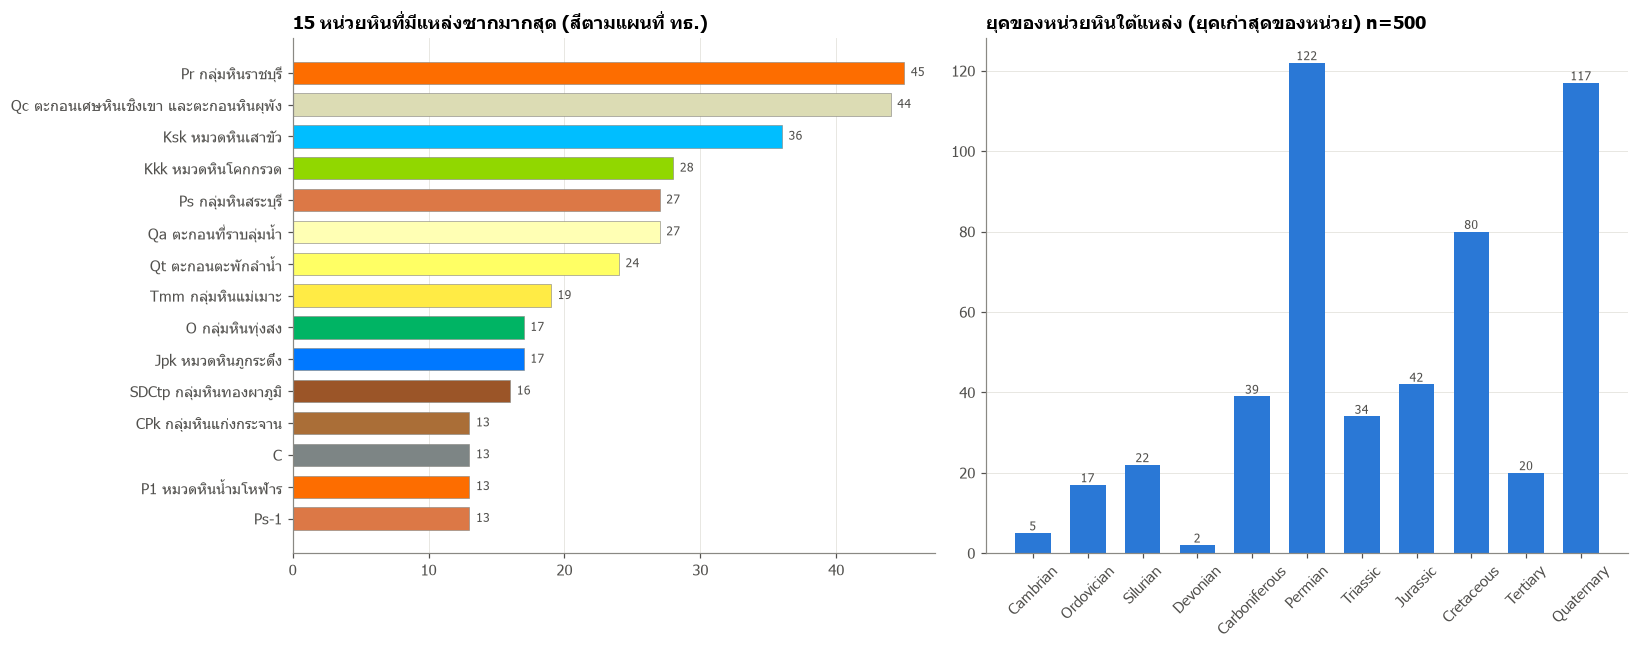

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
u = sites.unit_label.value_counts().head(15)
uc = legend.set_index("unit_label").color_hex
axes[0].barh(u.index[::-1], u.values[::-1], color=[uc.get(k, BAR) for k in u.index[::-1]], edgecolor="#8a8984", linewidth=0.4, height=0.7)
for y, v in enumerate(u.values[::-1]):
    axes[0].text(v + 0.5, y, str(v), va="center", fontsize=8, color="#52514e")
axes[0].set_title("15 หน่วยหินที่มีแหล่งซากมากสุด (สีตามแผนที่ ทธ.)")
axes[0].grid(axis="y", visible=False)

mp = sites.map_period_old.value_counts().reindex([p for p in PERIODS if p in set(sites.map_period_old.dropna())])
axes[1].bar(mp.index, mp.values, color=BAR, width=0.65)
for x, v in enumerate(mp.values):
    axes[1].text(x, v, str(v), ha="center", va="bottom", fontsize=8, color="#52514e")
axes[1].set_title(f"ยุคของหน่วยหินใต้แหล่ง (ยุคเก่าสุดของหน่วย) n={mp.sum()}")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
print(sites.rock_kind.value_counts(dropna=False).to_string())

**ตรวจความสอดคล้อง** ระหว่างยุคที่บันทึกในข้อมูลแหล่ง (`PERIODFROM`) กับยุคของหน่วยหินบนแผนที่
นับว่าสอดคล้องเมื่อช่วงยุคทั้งสองซ้อนทับกัน ถ้าไม่สอดคล้อง อาจเป็นเพราะพิกัดคลาดเคลื่อน
แผนที่มาตรา 1:250,000 หยาบเกินไป หรือซากอยู่ในตะกอนที่อายุอ่อนกว่า/ถูกพัดพามา

In [23]:
both = sites.dropna(subset=["period_old", "map_period_old"]).copy()
r = lambda s: s.map(P_RANK)
both["agree"] = (r(both.period_old) <= r(both.map_period_young)) & (r(both.map_period_old) <= r(both.period_young))
print(f"มีทั้งสองแหล่งข้อมูล {len(both)} แหล่ง | สอดคล้อง {both.agree.mean():.0%}")
display(pd.crosstab(both.period_old, both.map_period_old).reindex(index=[p for p in PERIODS if p in set(both.period_old)],
                                                                  columns=[p for p in PERIODS if p in set(both.map_period_old)]))
both.loc[~both.agree, ["NAME_TH", "PROVINCE", "PERIODFROM", "FORMATION", "unit_label"]].head(15)

มีทั้งสองแหล่งข้อมูล 161 แหล่ง | สอดคล้อง 60%


map_period_old,Ordovician,Silurian,Carboniferous,Permian,Triassic,Jurassic,Cretaceous,Quaternary
period_old,,,,,,,,
Cambrian,1,0,0,0,0,0,0,0
Ordovician,2,3,0,0,0,0,0,2
Devonian,0,1,0,0,0,0,0,0
Carboniferous,0,2,4,5,0,0,0,7
Permian,0,0,11,34,2,0,0,38
Triassic,0,0,0,3,13,0,0,4
Jurassic,0,0,0,0,0,12,2,1
Cretaceous,0,0,0,0,0,1,10,0
Quaternary,0,0,0,0,0,0,0,3


,NAME_TH,PROVINCE,PERIODFROM,FORMATION,unit_label
19,สัตว์ไม่มีกระดูกสันหลัง ถ้ำฤาษี - ถ้ำลูกเสือ,พังงา,เพอร์เมียน,พับผ้า,Qmc ตะกอนชายฝั่งทะเลโดยอิทธิพลของน้ำขึ้น
44,สัตว์มีกระดูกสันหลังถ้ำอุไรทอง,สตูล,ออร์โดวิเชียน,NaN,Qa ตะกอนที่ราบลุ่มน้ำ
45,สัตว์มีกระดูกสันหลังถ้ำหลังคอกวัว,กระบี่,เพอร์เมียน,NaN,Qc ตะกอนเศษหินเชิงเขา และตะกอนหินผุพัง
68,สัตว์ไม่มีกระดูกสันหลังวัดป่าเขากลิ้ง,เพชรบุรี,เพอร์เมียน,พับผ้า,Qc ตะกอนเศษหินเชิงเขา และตะกอนหินผุพัง
106,สัตว์ไม่มีกระดูกสันหลังอ่าวตะโล๊ะวาว,สตูล,แคมเบรียนตอนปลาย,NaN,O กลุ่มหินทุ่งสง
117,ไม้กลายเป็นหินห้วยขุนกระเจียก,พิษณุโลก,ไทรแอสสิก,NaN,Qt ตะกอนตะพักลำน้ำ
119,สัตว์ไม่มีกระดูกสันหลังเขาล่องเรือตาหมี่น,พิษณุโลก,คาร์บอนิเฟอรัส,ผาท่าพล,Ps กลุ่มหินสระบุรี
120,สัตว์ไม่มีกระดูกสันหลังถ้ำเดือนถ้ำดาว,พิษณุโลก,คาร์บอนิเฟอรัส,ผาท่าพล,Ps กลุ่มหินสระบุรี
122,ปะการังเขาผาหมาตาย,พิษณุโลก,คาร์บอนิเฟอรัส,ผาท่าพล,Ps กลุ่มหินสระบุรี
123,สัตว์ไม่มีกระดูกสันหลังถ้ำค้างคาว,พิษณุโลก,คาร์บอนิเฟอรัส,ผาท่าพล,Ps กลุ่มหินสระบุรี


แหล่งยุคจูแรสซิก (รวมช่วงที่ครอบคลุม): 45


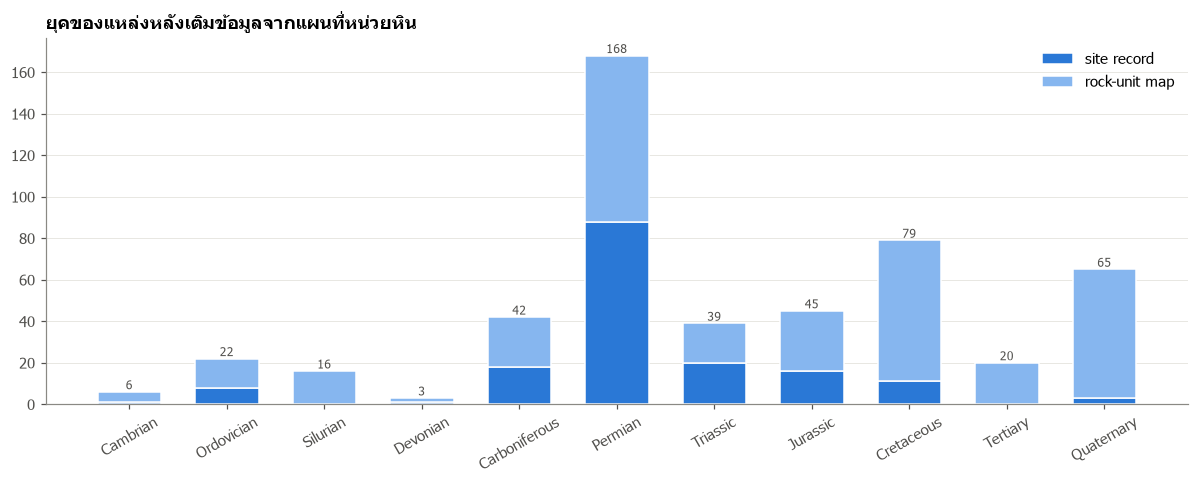

In [24]:
# เติมยุคที่หายไปด้วยยุคจากแผนที่ (ระบุแหล่งที่มาไว้ในคอลัมน์ period_source)
sites["period_best"] = sites.period_old.fillna(sites.map_period_old)
sites["period_source"] = np.select([sites.period_old.notna(), sites.map_period_old.notna()], ["site record", "rock-unit map"], "unknown")
pb = pd.crosstab(sites.period_best, sites.period_source).reindex([p for p in PERIODS if p in set(sites.period_best.dropna())])

fig, ax = plt.subplots(figsize=(11, 4.5))
bottom = np.zeros(len(pb))
for src, col in [("site record", "#2a78d6"), ("rock-unit map", "#86b6ef")]:
    ax.bar(pb.index, pb[src], bottom=bottom, color=col, label=src, width=0.65, edgecolor="white", linewidth=1)
    bottom += pb[src].values
for x, v in enumerate(bottom):
    ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_title("ยุคของแหล่งหลังเติมข้อมูลจากแผนที่หน่วยหิน")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
print(f"แหล่งยุคจูแรสซิก (รวมช่วงที่ครอบคลุม): {(sites.period_best.eq('Jurassic') | (sites.period_young.eq('Jurassic')) | sites.map_period_young.eq('Jurassic')).sum()}")

## 6. เชื่อมสองชุดข้อมูล

ทะเบียนตัวอย่าง**ไม่มีพิกัดและไม่มีรหัสแหล่ง** จึงเชื่อมได้แค่ระดับจังหวัดและอำเภอ
(คีย์อำเภอผ่าน `norm_district`: ตัดคำว่า "อำเภอ", แก้คำผิด, และแปลง "เมือง" เป็น "เมือง<จังหวัด>")

### 6.1 ระดับจังหวัด

In [25]:
p_spec = fl.groupby("province").agg(specimens=("fossil_id", "size"), spec_vert=("f_group", lambda s: (s == "Vertebrate").mean()))
p_site = sites.groupby("PROVINCE").agg(sites=("OBJECTID", "size"), site_vert=("Vertebrate", "mean"))
prov_tbl = p_spec.join(p_site, how="outer").fillna({"specimens": 0, "sites": 0}).astype({"specimens": int, "sites": int})
prov_tbl["specimens_per_site"] = (prov_tbl.specimens / prov_tbl.sites.replace(0, np.nan)).round(1)

only_spec = prov_tbl.query("sites == 0 and specimens > 0").sort_values("specimens", ascending=False)
only_site = prov_tbl.query("specimens == 0 and sites > 0")
print(f"จังหวัดที่มีทั้งสองชุด: {((prov_tbl.sites > 0) & (prov_tbl.specimens > 0)).sum()}")
print(f"มีตัวอย่างแต่ไม่มีแหล่งในฐานข้อมูลแหล่ง ({len(only_spec)}):", ", ".join(f"{k} ({v})" for k, v in only_spec.specimens.items()))
print(f"มีแหล่งแต่ไม่มีตัวอย่าง ({len(only_site)}):", ", ".join(only_site.index))
prov_tbl.sort_values("specimens", ascending=False).head(15)

จังหวัดที่มีทั้งสองชุด: 38
มีตัวอย่างแต่ไม่มีแหล่งในฐานข้อมูลแหล่ง (20): สมุทรสาคร (247), จันทบุรี (59), ประจวบคีรีขันธ์ (37), สุพรรณบุรี (30), เชียงใหม่ (24), ลำพูน (24), แม่ฮ่องสอน (14), หนองคาย (13), ภูเก็ต (10), กรุงเทพมหานคร (6), ยะลา (2), สุโขทัย (2), ฉะเชิงเทรา (2), พระนครศรีอยุธยา (1), นครนายก (1), ตราด (1), สุรินทร์ (1), ชลบุรี (1), เชียงราย (1), ระนอง (1)
มีแหล่งแต่ไม่มีตัวอย่าง (1): ร้อยเอ็ด


,specimens,spec_vert,sites,site_vert,specimens_per_site
province,,,,,
กาฬสินธุ์,2509,0.997609,22,0.863636,114.0
ชัยภูมิ,1188,0.989057,21,0.476190,56.6
เลย,799,0.066333,40,0.050000,20.0
ขอนแก่น,507,0.899408,16,0.750000,31.7
กระบี่,306,0.633987,17,0.235294,18.0
กาญจนบุรี,261,0.011494,15,0.133333,17.4
พะเยา,249,0.939759,2,1.000000,124.5
สมุทรสาคร,247,0.995951,0,NaN,NaN
สกลนคร,230,0.991304,5,0.800000,46.0


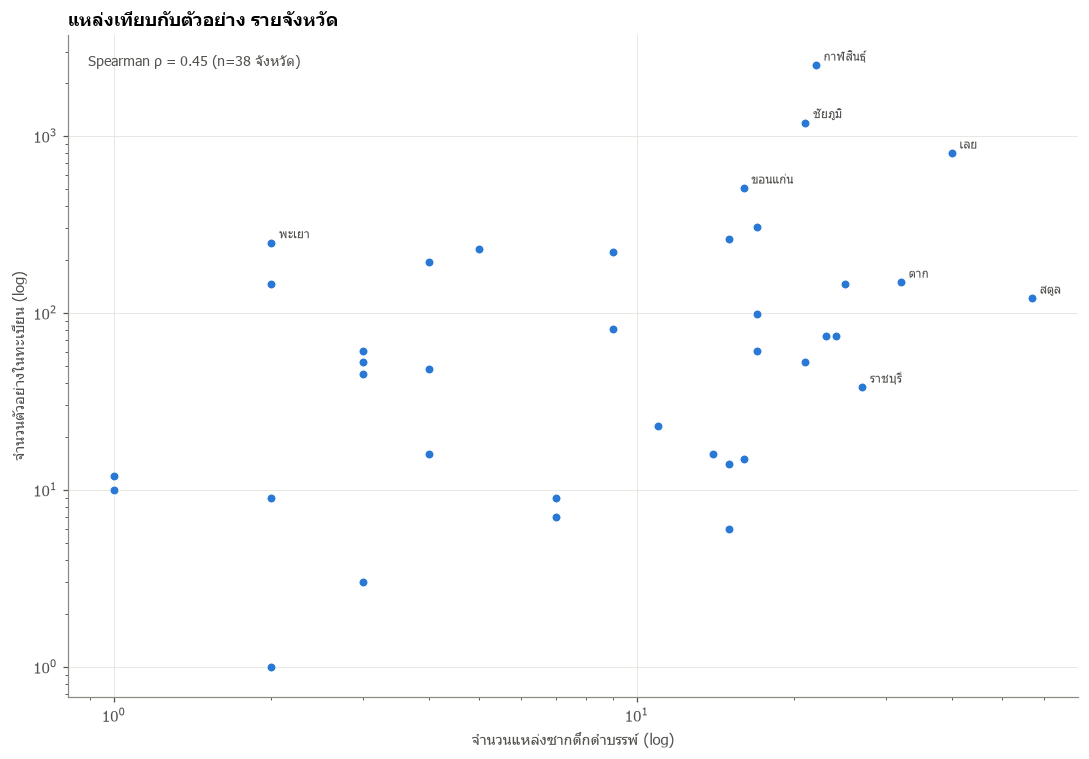

In [26]:
both_p = prov_tbl.query("sites > 0 and specimens > 0")
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(both_p.sites, both_p.specimens, s=36, color=BAR, edgecolor="white", linewidth=0.8, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
for name, r in both_p.iterrows():
    if r.specimens >= 500 or r.sites >= 27 or r.specimens_per_site >= 100:
        ax.annotate(name, (r.sites, r.specimens), textcoords="offset points", xytext=(5, 3), fontsize=8, color="#52514e")
ax.set_xlabel("จำนวนแหล่งซากดึกดำบรรพ์ (log)")
ax.set_ylabel("จำนวนตัวอย่างในทะเบียน (log)")
ax.set_title("แหล่งเทียบกับตัวอย่าง รายจังหวัด")
rho = both_p[["sites", "specimens"]].corr(method="spearman").iat[0, 1]
ax.text(0.02, 0.97, f"Spearman ρ = {rho:.2f} (n={len(both_p)} จังหวัด)", transform=ax.transAxes, va="top", fontsize=9, color="#52514e")
plt.tight_layout()

จังหวัดที่มีตัวอย่างต่อแหล่งสูงมาก (เช่น กาฬสินธุ์ ชัยภูมิ) คือแหล่งขุดค้นไดโนเสาร์ที่ขุดอย่างเข้มข้น
ส่วนจังหวัดที่มีแหล่งมากแต่ตัวอย่างน้อย (เช่น สตูล ตาก ราชบุรี) คือแหล่งอ้างอิงทางวิชาการที่ยังไม่มีตัวอย่างลงทะเบียน

### 6.2 ระดับอำเภอ

In [27]:
site_districts = set(zip(sites.PROVINCE, sites.district_key))
has_loc = fl.province.notna() & fl.district_key.notna()
fl["district_has_site"] = [(p, d) in site_districts for p, d in zip(fl.province, fl.district_key)]

cov = fl[has_loc].groupby("f_group", observed=True).district_has_site.mean().reindex(GROUP_ORDER)
print(f"ตัวอย่างที่ระบุอำเภอ: {has_loc.sum():,} | อยู่ในอำเภอที่มีแหล่งใน ทธ. site DB: {fl.loc[has_loc, 'district_has_site'].mean():.0%}")
display(cov.rename("share_in_district_with_site").to_frame().style.format("{:.0%}"))

d_tbl = (fl[has_loc].groupby(["province", "district_key"]).agg(specimens=("fossil_id", "size"), has_site=("district_has_site", "first"))
         .sort_values("specimens", ascending=False))
print("อำเภอที่มีตัวอย่างมากแต่ไม่มีแหล่งในฐานข้อมูลแหล่ง:")
d_tbl.query("not has_site").head(12)

ตัวอย่างที่ระบุอำเภอ: 7,816 | อยู่ในอำเภอที่มีแหล่งใน ทธ. site DB: 81%


,share_in_district_with_site
f_group,
Vertebrate,83%
Invertebrate,78%
Plant,76%
Trace fossil,86%
Other,62%


อำเภอที่มีตัวอย่างมากแต่ไม่มีแหล่งในฐานข้อมูลแหล่ง:


,,specimens,has_site
province,district_key,,
สมุทรสาคร,บ้านแพ้ว,246,False
ขอนแก่น,ภูเวียง,239,False
กาฬสินธุ์,ภูน้อย,152,False
สกลนคร,เต่างอย,96,False
กระบี่,เหนือคลอง,92,False
ตรัง,กันตัง,59,False
จันทบุรี,นายายอาม,51,False
นครสวรรค์,ตาคลี,35,False
กาญจนบุรี,ไทรโยค,34,False


อำเภอที่ไม่ตรงกันบางส่วนเกิดจาก**เขตการปกครองที่เปลี่ยนไป** ไม่ใช่ว่าไม่มีแหล่งจริง เช่น
ตัวอย่างจาก "ภูเวียง" (ขอนแก่น) ตรงกับแหล่งในฐานข้อมูลแหล่งที่บันทึกเป็น "เวียงเก่า" ซึ่งแยกออกมาจากอำเภอภูเวียง
การเชื่อมระดับอำเภอจึงเป็นค่าต่ำสุด ถ้าจะเชื่อมให้แม่นยำต้องมีพิกัดหรือรหัสแหล่งในทะเบียนตัวอย่าง

### 6.3 ไดโนเสาร์: ตัวอย่าง vs แหล่ง

In [28]:
dino_p = pd.DataFrame({
    "dino_specimens": dino.province.value_counts(),
    "dino_sites": sites[sites.is_dinosaur].PROVINCE.value_counts(),
}).fillna(0).astype(int).sort_values("dino_specimens", ascending=False)
dino_p["note"] = np.select([dino_p.dino_sites.eq(0), dino_p.dino_specimens.eq(0)], ["ไม่มีแหล่งไดโนเสาร์ใน site DB", "ยังไม่มีตัวอย่างในทะเบียน"], "")
dino_p

,dino_specimens,dino_sites,note
กาฬสินธุ์,2046,14,
ชัยภูมิ,442,8,
ขอนแก่น,432,12,
พะเยา,94,1,
เลย,44,5,
นครราชสีมา,30,14,
มุกดาหาร,12,5,
กระบี่,5,0,ไม่มีแหล่งไดโนเสาร์ใน site DB
หนองบัวลำภู,3,6,
อุดรธานี,2,0,ไม่มีแหล่งไดโนเสาร์ใน site DB


## 7. สรุปข้อค้นพบและปัญหาคุณภาพข้อมูล

**ข้อค้นพบหลัก**
- ทะเบียนตัวอย่าง (8,521 ชิ้น) เน้น**ไดโนเสาร์และสัตว์มีกระดูกสันหลัง**ในภาคอีสาน (กาฬสินธุ์ ชัยภูมิ เลย ขอนแก่น) ซึ่งกระจุกตัวสูงมาก
- ฐานข้อมูลแหล่ง (518 แห่ง) เน้น**สัตว์ไม่มีกระดูกสันหลังทะเลยุคพาลีโอโซอิก** (เพอร์เมียน คาร์บอนิเฟอรัส) ในภาคใต้และตะวันตก (สตูล ตาก ราชบุรี)
- สองชุดจึง**เสริมกัน**มากกว่าซ้ำกัน ชุดหนึ่งบอกว่ามีตัวอย่างอะไร อีกชุดบอกว่าแหล่งอยู่ที่ไหน
- การซ้อนกับแผนที่หน่วยหินช่วยเติมยุคให้แหล่งที่ไม่ได้บันทึกยุคไว้ได้

**ปัญหาคุณภาพข้อมูลที่ต้องระวัง**

| ชุดข้อมูล | ปัญหา | การจัดการใน notebook |
|---|---|---|
| ทะเบียนตัวอย่าง | 3 ระเบียนส่งออกผิด (ท้ายแถวหลุดไปบรรทัดใหม่) | `read_fossil_list` ซ่อมให้ |
| ทะเบียนตัวอย่าง | ค่าแทนที่ว่าง (`ไม่ระบุ`, `N/A`) และ `N/A (กลุ่ม)` ใน `sci_name` | แปลงเป็น NA และแยก `identified` / `broad_taxon` |
| ทะเบียนตัวอย่าง | ไม่มีพิกัดและรหัสแหล่ง | เชื่อมได้แค่ระดับจังหวัด/อำเภอ |
| ทะเบียนตัวอย่าง | `f_part`, `dis_name` เป็นข้อความอิสระ สะกดไม่เป็นมาตรฐาน | ยังไม่ได้จัดกลุ่ม |
| ทะเบียนตัวอย่าง | `fossil_id` บอกรอบการนำเข้าข้อมูล ไม่ใช่วันที่ค้นพบ | ใช้ดูได้แค่ประวัติการนำเข้า |
| แหล่ง | หลายคอลัมน์ว่างทั้งหมด (`DIS_YEAR`, `PERIODTO`, `POTENTIAL*` ฯลฯ) | ตัดออก |
| แหล่ง | `PERIODFROM` ว่างเป็นส่วนใหญ่ และสะกดหลายแบบ | `parse_period_th` + เติมจากแผนที่ |
| แหล่ง | `SITE_CODE` ซ้ำกันบางแหล่ง | ใช้ `OBJECTID` เป็นคีย์ |
| แหล่ง | `FOS_GR_*` มีช่องว่างต่อท้าย | `clean_th` |
| ทั้งสอง | ชื่ออำเภอสะกดต่างกัน (`เมือง` vs `เมือง<จังหวัด>`, `กาฬสินธ์`, `สตูน`) | `norm_district` |

**ต่อยอด**: ใช้ DEM (`data/dem/`) และภาพ Sentinel-2 รอบแต่ละแหล่ง (`data/sentinel2_sites/`) วิเคราะห์ภูมิประเทศ
หรือเทียบกับ PBDB (`data/pbdb_thailand/`) เพื่อดูว่าแหล่งไหนมีงานตีพิมพ์แล้ว